# Peso de cada variable en el índice conjunto del embalse Neusa

Este cuaderno responde una pregunta: **¿cuánto pesa cada medición en un índice que resume el embalse de Neusa y su ambiente en agosto de 2024?**

Se usan el volumen publicado por la CAR, convertido en una distancia simulada, y cuatro variables meteorológicas de NASA POWER. El cuaderno `01_Fusion_ACP_volumen_ambiente.ipynb` explica la construcción de la matriz, el fundamento físico y la definición de los porcentajes; aquí no se repite.

## Resultado en una página

> **Pregunta:** ¿cuánto pesa cada variable en el índice principal?

Cada fila de la tabla es una variable. La columna `ponderaje_final_pct` suma 100 %. El intervalo de confianza del 95 % (`IC95`) se obtuvo con 1000 remuestreos de las observaciones. Las etiquetas de sensor son una correspondencia prevista para el firmware: **no son ponderaciones de riesgo validadas**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

BASE = Path.cwd()
VARIABLES_ACP = ["distancia_simulada_cm", "radiacion_MJ_m2_dia", "temperatura_media_C",
                 "humedad_relativa_pct", "presion_hPa"]
QUE_ES = {
    "distancia_simulada_cm": "Sensor ultrasónico previsto para el nivel. Aquí es una distancia simulada a partir del volumen publicado, no una medición.",
    "radiacion_MJ_m2_dia": "Rol previsto de la luz (LDR). Es radiación solar de NASA POWER, no una lectura de un LDR.",
    "temperatura_media_C": "Sensor DHT previsto. Aquí el valor viene de NASA POWER.",
    "humedad_relativa_pct": "Sensor DHT previsto. Aquí el valor viene de NASA POWER.",
    "presion_hPa": "Sensor BMP previsto. Aquí el valor viene de NASA POWER.",
}
assert set(QUE_ES) == set(VARIABLES_ACP)
B_REMUESTREOS = 1000
SEMILLA_BOOTSTRAP = 42
UMBRAL_ALINEACION = 0.9

def ponderajes_pc1(X):
    """Coeficientes de PC1, ponderaje cuadrático (%) y sensibilidad L1 (%) para una matriz sin estandarizar."""
    Z = StandardScaler().fit_transform(X)
    a = PCA(svd_solver="full").fit(Z).components_[0]
    return a, 100 * a ** 2 / np.sum(a ** 2), 100 * np.abs(a) / np.abs(a).sum()

def bootstrap_ponderajes(X, a_ref):
    """Remuestreo con reemplazo de las filas; semilla fija. Devuelve ponderajes por remuestreo y alineación con PC1 de referencia."""
    rng = np.random.RandomState(SEMILLA_BOOTSTRAP)
    n = X.shape[0]
    cuadraticos, l1, alineacion = [], [], []
    for _ in range(B_REMUESTREOS):
        idx = rng.randint(0, n, size=n)
        a, c, l = ponderajes_pc1(X[idx])
        cuadraticos.append(c)
        l1.append(l)
        alineacion.append(abs(a @ a_ref) / (np.linalg.norm(a) * np.linalg.norm(a_ref)))
    return np.array(cuadraticos), np.array(l1), np.array(alineacion)

matriz = (pd.read_csv(BASE / "resultados/datos_neusa_con_distancia_simulada.csv", parse_dates=["fecha"])
          .set_index("fecha").sort_index())
X_top = matriz[VARIABLES_ACP].to_numpy(float)
assert X_top.shape == (31, 5)
a_ref, cuad_pt, l1_pt = ponderajes_pc1(X_top)
cuad_boot, l1_boot, alin_boot = bootstrap_ponderajes(X_top, a_ref)
ic_inf, ic_sup = np.percentile(cuad_boot, [2.5, 97.5], axis=0)
resumen_pagina = pd.DataFrame({
    "ponderaje_final_pct": cuad_pt,
    "IC95_inferior_pct": ic_inf,
    "IC95_superior_pct": ic_sup,
    "sensibilidad_L1_pct": l1_pt,
    "qué es": pd.Series(QUE_ES),
}, index=VARIABLES_ACP)
assert abs(resumen_pagina["ponderaje_final_pct"].sum() - 100) < 1e-9
assert abs(resumen_pagina["sensibilidad_L1_pct"].sum() - 100) < 1e-9
display(resumen_pagina.round(2))

,ponderaje_final_pct,IC95_inferior_pct,IC95_superior_pct,sensibilidad_L1_pct,qué es
distancia_simulada_cm,13.76,0.16,26.01,17.34,Sensor ultrasónico previsto para el nivel. Aqu...
radiacion_MJ_m2_dia,3.87,0.01,19.67,9.20,Rol previsto de la luz (LDR). Es radiación sol...
temperatura_media_C,28.37,19.90,39.11,24.89,Sensor DHT previsto. Aquí el valor viene de NA...
humedad_relativa_pct,26.91,8.81,31.98,24.25,Sensor DHT previsto. Aquí el valor viene de NA...
presion_hPa,27.09,17.64,39.53,24.33,Sensor BMP previsto. Aquí el valor viene de NA...


Fuente de los números de esta sección: la celda anterior. La sección *Ponderajes finales* vuelve a calcular los mismos valores desde las fuentes crudas y verifica que coinciden.

## Cómo leer este cuaderno

### Glosario

- **ACP (análisis de componentes principales):** técnica que resume varias variables en nuevas variables llamadas componentes, ordenadas de mayor a menor información.
- **Componente principal (PC1, PC2…):** combinación de todas las variables. PC1 es la que captura más variación común.
- **Varianza explicada:** porcentaje de la variación total que recoge un componente.
- **Coeficiente de PC1:** peso de cada variable dentro de PC1. Es el vector que usan los ponderajes de este cuaderno.
- **Carga:** correlación entre una variable y el puntaje de un componente. Se muestra en la figura 7b y no se usa para los ponderajes.
- **K-means:** método que separa las observaciones en un número k de grupos según su cercanía.
- **Silueta:** medida de en qué medida cada observación encaja en su grupo (de −1 a 1).
- **Bootstrap:** repetir el cálculo sobre muchas muestras obtenidas por remuestreo con reemplazo, para medir la incertidumbre.
- **Intervalo de confianza del 95 % (IC95):** rango entre los percentiles 2,5 y 97,5 de los valores del bootstrap.
- **Ponderaje final (método cuadrático):** coeficiente de PC1 elevado al cuadrado, dividido por la suma de los cuadrados y multiplicado por 100. Suma 100 %.
- **Método L1:** valor absoluto del coeficiente dividido por la suma de los valores absolutos. Suma 100 %. Es una sensibilidad comparativa, distinta del ponderaje final.

### ¿Qué es un ACP, en pocas líneas?

El ACP toma las variables de cada día y busca la combinación que mejor resume sus cambios conjuntos. Esa combinación es el componente PC1. La varianza explicada indica qué parte de la variación total recoge cada componente. Los coeficientes de PC1 dicen cuánto pesa cada variable en esa combinación, y el signo indica si la variable empuja el puntaje hacia arriba o hacia abajo.

## Punto 0. Fuentes y contexto

> **Pregunta:** ¿de dónde salen los datos?

Se usan tres archivos registrados en `datos/fuentes.json`: la tabla de embalses de la CAR para agosto de 2024, el JSON original de NASA POWER para el punto cercano al Neusa (2023–2025) y la tabla diaria derivada de NASA. Cada archivo se compara con su SHA-256 antes de usarse.

Escala de la distancia simulada: el volumen máximo del mes se asigna a 5 cm y el mínimo a 20 cm. Son extremos del mes, no un embalse lleno o seco. La escala no se ajusta para obtener proporciones predefinidas.

**Constantes del cuaderno**

- `UMBRAL_VARIANZA_ACUMULADA = 80`: criterio mínimo de varianza acumulada del Parcial 2 para retener componentes. Es una constante declarada, no se calcula con los datos.
- `K_MAX = 6`: número máximo de grupos evaluados en K-means.
- `UMBRAL_REDUNDANCIA = 0.95`: correlación absoluta a partir de la cual una variable se considera redundante con otra incluida.

**Diccionario de variables (resumen)**

- CAR: `fecha`, `embalse`, `capacidad_util_Mm3`, `volumen_Mm3`, `almacenamiento_pct`, `descarga_m3_s`, `capacidad_regulacion_Mm3`, `tendencia_publicada`.
- NASA POWER: `temperatura_media_C`, `temperatura_max_C`, `temperatura_min_C` (°C), `humedad_relativa_pct` (%), `presion_kPa` y `presion_hPa` (`presion_hPa` = `presion_kPa` × 10), `radiacion_MJ_m2_dia`, `precipitacion_mm_dia`, `viento_2m_m_s`.
- Derivadas: `distancia_simulada_cm` (cm) y `descenso_relativo_simulado` = (distancia − 5) / 15.

In [2]:
import hashlib
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import importlib.metadata as md
from IPython.display import Markdown
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples, silhouette_score)
from sklearn.preprocessing import StandardScaler

assert (BASE / "datos/fuentes.json").is_file(), "Ejecutar el cuaderno desde la carpeta que contiene datos/."
RESULTADOS = BASE / "resultados"
EMBALSE = "Neusa"
MES_INICIO, MES_FIN = "2024-08-01", "2024-08-31"
DISTANCIA_MIN_CM, DISTANCIA_MAX_CM = 5.0, 20.0
UMBRAL_VARIANZA_ACUMULADA = 80.0
UMBRAL_REDUNDANCIA = 0.95
K_MAX = 6
SEMILLAS_ESTABILIDAD = [0, 1, 2, 3, 4]
SEMILLA_PRINCIPAL = 42
BLOQUE_AMBIENTAL = VARIABLES_ACP[1:]

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11})
versiones = pd.Series({p: md.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]},
                      name="versión")
display(versiones.to_frame())

fuentes = json.loads((BASE / "datos/fuentes.json").read_text(encoding="utf-8"))
por_archivo = {f["archivo"]: f for f in fuentes}
ARCHIVOS_USADOS = ["datos/car_embalses_agosto_2024.csv",
                   "datos/originales/nasa_power_neusa_2023_2025.json",
                   "datos/nasa_power_neusa_diario_2023_2025.csv"]
verificacion = []
for archivo in ARCHIVOS_USADOS:
    sha = hashlib.sha256((BASE / archivo).read_bytes()).hexdigest()
    verificacion.append({"archivo": archivo, "entidad": por_archivo[archivo]["entidad"],
                         "sha256_coincide": sha == por_archivo[archivo]["sha256"]})
verificacion = pd.DataFrame(verificacion)
display(verificacion)
assert verificacion["sha256_coincide"].all(), "Una fuente usada no coincide con su SHA-256 registrado."
n_pdf = sum(1 for f in fuentes if f["archivo"].endswith(".pdf"))
print(f"Manifiesto: {len(fuentes)} entradas, de ellas {n_pdf} boletines PDF de la CAR (no se leen en este cuaderno).")

car_crudo = pd.read_csv(BASE / "datos/car_embalses_agosto_2024.csv", parse_dates=["fecha"])
nasa_json = json.loads((BASE / "datos/originales/nasa_power_neusa_2023_2025.json").read_text(encoding="utf-8"))
PARAMETROS_NASA = {"T2M": "temperatura_media_C", "T2M_MAX": "temperatura_max_C",
                   "T2M_MIN": "temperatura_min_C", "RH2M": "humedad_relativa_pct",
                   "PS": "presion_kPa", "ALLSKY_SFC_SW_DWN": "radiacion_MJ_m2_dia",
                   "PRECTOTCORR": "precipitacion_mm_dia", "WS2M": "viento_2m_m_s"}
VALOR_FALTANTE_NASA = nasa_json["header"]["fill_value"]
assert nasa_json["header"]["time_standard"] == "LST"
assert nasa_json["parameters"]["PS"]["units"] == "kPa"
nasa_crudo = pd.DataFrame({nombre: pd.Series(nasa_json["properties"]["parameter"][codigo], dtype=float)
                           for codigo, nombre in PARAMETROS_NASA.items()})
nasa_crudo.index = pd.to_datetime(nasa_crudo.index, format="%Y%m%d")
nasa_crudo.index.name = "fecha"
nasa_crudo = nasa_crudo.sort_index()
print("CAR (filas, columnas):", car_crudo.shape, "| NASA (filas, columnas):", nasa_crudo.shape)

,versión
numpy,2.4.6
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2


,archivo,entidad,sha256_coincide
0,datos/car_embalses_agosto_2024.csv,Tabla derivada,True
1,datos/originales/nasa_power_neusa_2023_2025.json,NASA POWER,True
2,datos/nasa_power_neusa_diario_2023_2025.csv,Tabla derivada,True


Manifiesto: 34 entradas, de ellas 31 boletines PDF de la CAR (no se leen en este cuaderno).
CAR (filas, columnas): (124, 9) | NASA (filas, columnas): (1096, 8)


La tabla diaria derivada de NASA (`datos/nasa_power_neusa_diario_2023_2025.csv`) se contrasta con el JSON original en las columnas comunes. Cualquier diferencia mayor que 1e-9 detiene el cuaderno.

In [3]:
nasa_csv = (pd.read_csv(BASE / "datos/nasa_power_neusa_diario_2023_2025.csv", parse_dates=["fecha"])
            .set_index("fecha").sort_index())
assert nasa_csv.index.equals(nasa_crudo.index), "Las fechas de la tabla derivada no coinciden con el JSON."
columnas_nasa_comunes = [c for c in nasa_crudo.columns if c in nasa_csv.columns]
diferencia_derivada = (nasa_crudo[columnas_nasa_comunes] - nasa_csv[columnas_nasa_comunes]).abs().max()
assert diferencia_derivada.max() < 1e-9, "La tabla NASA derivada no coincide con el JSON original."
print(f"Columnas comunes comparadas: {len(columnas_nasa_comunes)}; diferencia absoluta máxima: {diferencia_derivada.max():.3e}")

Columnas comunes comparadas: 8; diferencia absoluta máxima: 0.000e+00


## Punto 1. Exploración inicial

> **Pregunta:** ¿cómo son los datos antes de tocarlos?

Cada tabla tiene una clave que identifica sus filas. En CAR la clave es el día y el embalse: una fila por embalse y día. En NASA la clave es el día: una fila por día. Se verifica que ambas claves se cumplan, que NASA no tenga huecos y que no existan valores de relleno (−999).

In [4]:
granularidad = pd.DataFrame({
    "filas": [len(car_crudo), len(nasa_crudo)],
    "columnas": [car_crudo.shape[1], nasa_crudo.shape[1]],
    "clave_de_fila": ["fecha + embalse", "fecha"],
    "claves_unicas": [len(car_crudo.drop_duplicates(["fecha", "embalse"])), nasa_crudo.index.nunique()],
}, index=["CAR", "NASA POWER"])
display(granularidad)
assert nasa_crudo.index.equals(pd.date_range("2023-01-01", "2025-12-31", name="fecha")), "NASA no es diaria y completa."
print("NASA: una fila por día, sin huecos, de 2023-01-01 a 2025-12-31.")
display(car_crudo.groupby("embalse").size().rename("filas").to_frame())
centinelas_crudos = int((nasa_crudo == VALOR_FALTANTE_NASA).sum().sum())
print(f"Valores de relleno {VALOR_FALTANTE_NASA} en NASA (crudos): {centinelas_crudos}")
display(car_crudo.select_dtypes("number").describe().T[["mean", "std", "min", "max"]].round(3))
display(nasa_crudo[["temperatura_media_C", "humedad_relativa_pct", "radiacion_MJ_m2_dia"]]
        .describe().T[["mean", "std", "min", "max"]].round(3))

,filas,columnas,clave_de_fila,claves_unicas
CAR,124,9,fecha + embalse,124
NASA POWER,1096,8,fecha,1096


NASA: una fila por día, sin huecos, de 2023-01-01 a 2025-12-31.


,filas
embalse,
El Hato,31
Neusa,31
Sisga,31
Tominé,31


Valores de relleno -999.0 en NASA (crudos): 0


,mean,std,min,max
capacidad_util_Mm3,223.650,272.245,12.700,689.500
volumen_Mm3,129.523,138.217,10.327,367.222
almacenamiento_pct,71.024,11.273,51.990,82.860
descarga_m3_s,1.905,2.185,0.000,6.000
capacidad_regulacion_Mm3,94.139,134.590,2.180,331.030


,mean,std,min,max
temperatura_media_C,13.967,0.879,10.93,16.60
humedad_relativa_pct,87.301,3.160,63.02,94.69
radiacion_MJ_m2_dia,16.436,3.112,7.04,26.22


Duplicados por clave: CAR = 0; NASA = 0
Filas completas repetidas: CAR = 0; NASA = 0


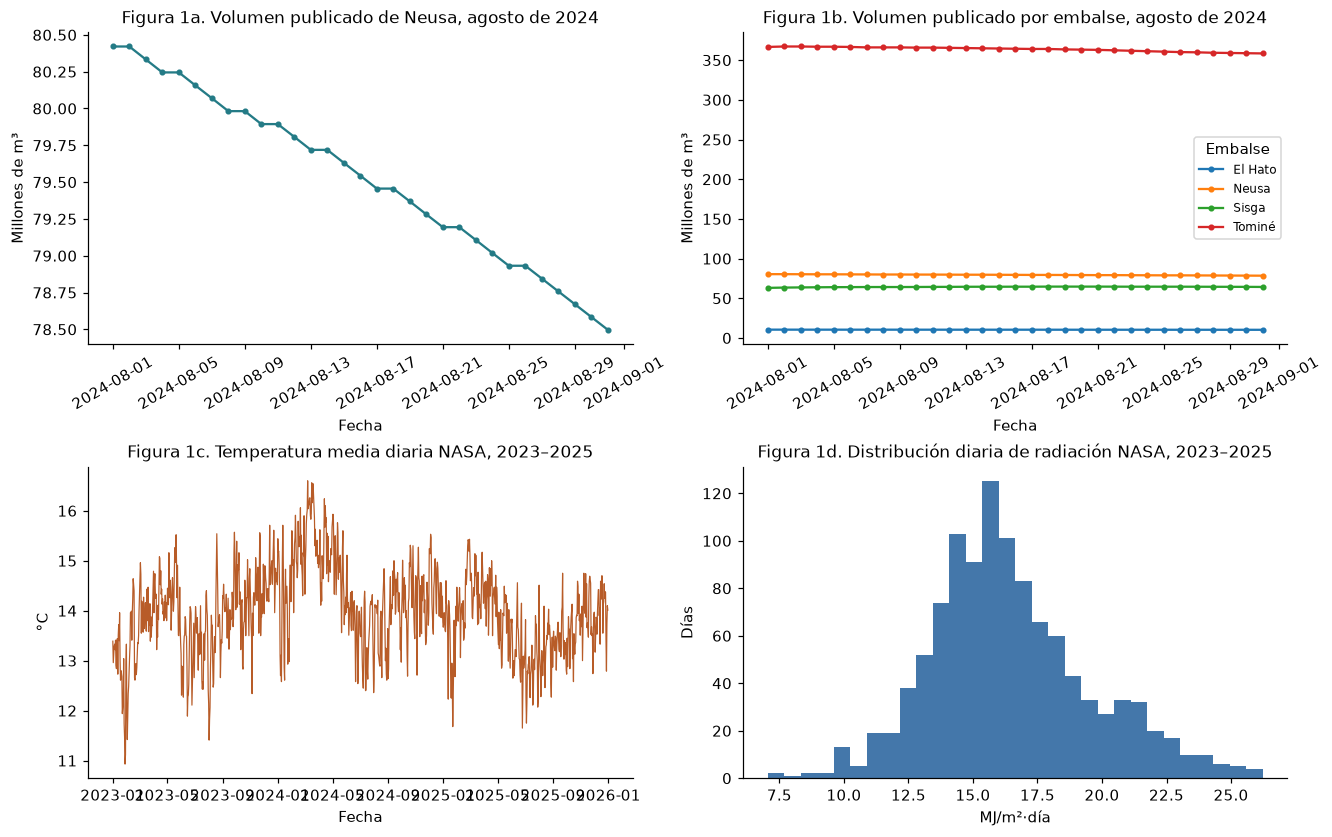

In [5]:
dup_clave_car = int(car_crudo.duplicated(["fecha", "embalse"]).sum())
dup_clave_nasa = int(nasa_crudo.index.duplicated().sum())
print(f"Duplicados por clave: CAR = {dup_clave_car}; NASA = {dup_clave_nasa}")
print(f"Filas completas repetidas: CAR = {int(car_crudo.duplicated().sum())}; NASA = {int(nasa_crudo.reset_index().duplicated().sum())}")

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
serie_neusa = car_crudo.loc[car_crudo["embalse"].eq(EMBALSE)].set_index("fecha").sort_index()["volumen_Mm3"]
ejes[0, 0].plot(serie_neusa.index, serie_neusa.values, marker="o", ms=3, color="#247b86")
ejes[0, 0].set(title="Figura 1a. Volumen publicado de Neusa, agosto de 2024",
               xlabel="Fecha", ylabel="Millones de m³")
ejes[0, 0].tick_params(axis="x", rotation=30)
for embalse, grupo in car_crudo.groupby("embalse"):
    g = grupo.set_index("fecha").sort_index()
    ejes[0, 1].plot(g.index, g["volumen_Mm3"], marker=".", label=embalse)
ejes[0, 1].set(title="Figura 1b. Volumen publicado por embalse, agosto de 2024",
               xlabel="Fecha", ylabel="Millones de m³")
ejes[0, 1].legend(title="Embalse", fontsize=8)
ejes[0, 1].tick_params(axis="x", rotation=30)
ejes[1, 0].plot(nasa_crudo.index, nasa_crudo["temperatura_media_C"], color="#b85c28", lw=0.8)
ejes[1, 0].set(title="Figura 1c. Temperatura media diaria NASA, 2023–2025", xlabel="Fecha", ylabel="°C")
ejes[1, 1].hist(nasa_crudo["radiacion_MJ_m2_dia"].dropna(), bins=30, color="#4477AA")
ejes[1, 1].set(title="Figura 1d. Distribución diaria de radiación NASA, 2023–2025",
               xlabel="MJ/m²·día", ylabel="Días")
plt.show()

Leyenda de la figura 1: los paneles muestran el volumen de Neusa y de los cuatro embalses en agosto, y la distribución diaria de NASA en 2023–2025.

## Punto 2. Preparación

> **Pregunta:** ¿hay datos repetidos, faltantes o con formato incorrecto?

Las tablas originales no se modifican; el trabajo se hace sobre copias. Reglas por variable, sin pérdida de filas:

| Columna o grupo | Regla |
|---|---|
| CAR | Sin imputación. Un faltante detendría la preparación. |
| NASA, variables meteorológicas | Valor de relleno → vacío; luego interpolación temporal lineal con límite de 2 días. |
| `presion_hPa` | Conversión exacta (kPa × 10); no es imputación. |
| Distancia simulada | Derivada del volumen observado; no tiene faltantes. |

In [6]:
car_trabajo = car_crudo.copy()
nasa_trabajo = nasa_crudo.copy()

antes_car, antes_nasa = len(car_trabajo), len(nasa_trabajo)
car_trabajo = car_trabajo.drop_duplicates(subset=["fecha", "embalse"], keep="first")
nasa_trabajo = nasa_trabajo[~nasa_trabajo.index.duplicated(keep="first")]
dup_eliminados_car = antes_car - len(car_trabajo)
dup_eliminados_nasa = antes_nasa - len(nasa_trabajo)
print(f"Deduplicación: CAR {antes_car} -> {len(car_trabajo)}; NASA {antes_nasa} -> {len(nasa_trabajo)}")
assert not car_trabajo.duplicated(["fecha", "embalse"]).any()
assert nasa_trabajo.index.is_unique

print(f"Faltantes antes del tratamiento: CAR = {int(car_trabajo.isna().sum().sum())}; NASA = {int(nasa_trabajo.isna().sum().sum())}")
n_centinela = int((nasa_trabajo == VALOR_FALTANTE_NASA).sum().sum())
nasa_trabajo = nasa_trabajo.replace(VALOR_FALTANTE_NASA, np.nan)
nan_antes_interpolar = int(nasa_trabajo.isna().sum().sum())
nasa_trabajo = nasa_trabajo.interpolate(method="time", limit=2, limit_direction="both")
imputados_nasa = nan_antes_interpolar - int(nasa_trabajo.isna().sum().sum())
nasa_trabajo["presion_hPa"] = nasa_trabajo["presion_kPa"] * 10

faltantes_car = int(car_trabajo.isna().sum().sum())
faltantes_nasa = int(nasa_trabajo.isna().sum().sum())
assert faltantes_car == 0, "CAR tiene faltantes; no hay regla de imputación para esta tabla."
assert faltantes_nasa == 0, "NASA conserva faltantes tras la interpolación limitada."
print(f"Valores de relleno sustituidos: {n_centinela}; valores imputados: {imputados_nasa}")
print(f"Faltantes tras el tratamiento: CAR = {faltantes_car}; NASA = {faltantes_nasa}")

Deduplicación: CAR 124 -> 124; NASA 1096 -> 1096
Faltantes antes del tratamiento: CAR = 0; NASA = 0
Valores de relleno sustituidos: 0; valores imputados: 0
Faltantes tras el tratamiento: CAR = 0; NASA = 0


Se unen las filas de Neusa en CAR con las filas de NASA de la misma fecha (unión interna, validación uno a uno). Solo se conservan las fechas con volumen publicado. La distancia simulada se calcula con el volumen máximo y mínimo observados del mes.

In [7]:
neusa = car_trabajo.loc[car_trabajo["embalse"].eq(EMBALSE)].set_index("fecha").sort_index()
filas_otros_embalses = int((~car_trabajo["embalse"].eq(EMBALSE)).sum())
base_mensual = neusa.join(nasa_trabajo, how="inner", validate="one_to_one")
base_mensual = base_mensual.loc[MES_INICIO:MES_FIN].copy()
dias_nasa_sin_volumen = len(nasa_trabajo) - len(base_mensual)

V_min = float(base_mensual["volumen_Mm3"].min())
V_max = float(base_mensual["volumen_Mm3"].max())
assert V_max > V_min
base_mensual["distancia_simulada_cm"] = DISTANCIA_MIN_CM + (DISTANCIA_MAX_CM - DISTANCIA_MIN_CM) * (
    V_max - base_mensual["volumen_Mm3"]) / (V_max - V_min)
base_mensual["descenso_relativo_simulado"] = (
    base_mensual["distancia_simulada_cm"] - DISTANCIA_MIN_CM) / (DISTANCIA_MAX_CM - DISTANCIA_MIN_CM)

assert len(base_mensual) == 31 and base_mensual.index.is_unique
assert base_mensual.index.min() == pd.Timestamp(MES_INICIO) and base_mensual.index.max() == pd.Timestamp(MES_FIN)
assert base_mensual[VARIABLES_ACP].notna().all().all()
assert base_mensual["distancia_simulada_cm"].between(DISTANCIA_MIN_CM, DISTANCIA_MAX_CM).all()
print(f"Filas de la base mensual: {len(base_mensual)}; columnas: {base_mensual.shape[1]}")
print(f"Volumen mínimo observado: {V_min:.3f} Mm³; máximo: {V_max:.3f} Mm³")

Filas de la base mensual: 31; columnas: 19
Volumen mínimo observado: 78.497 Mm³; máximo: 80.421 Mm³


Figura 2. Panel izquierdo: distancia simulada cada día del mes. Panel derecho: volumen frente a distancia, con relación lineal por construcción.

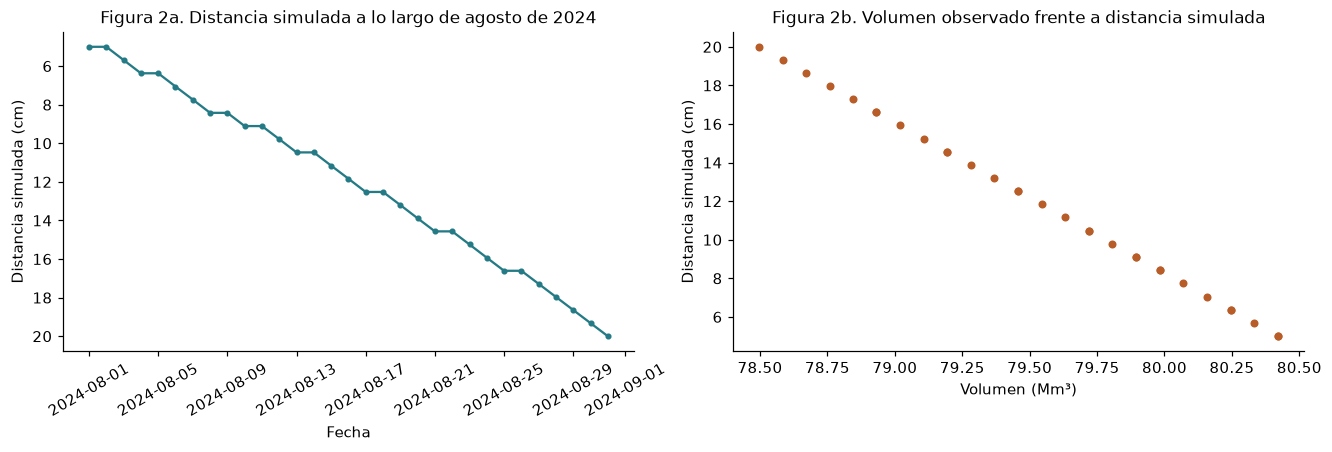

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ejes[0].plot(base_mensual.index, base_mensual["distancia_simulada_cm"], marker="o", ms=3, color="#247b86")
ejes[0].invert_yaxis()
ejes[0].set(title="Figura 2a. Distancia simulada a lo largo de agosto de 2024",
            xlabel="Fecha", ylabel="Distancia simulada (cm)")
ejes[0].tick_params(axis="x", rotation=30)
ejes[1].scatter(base_mensual["volumen_Mm3"], base_mensual["distancia_simulada_cm"], color="#b85c28", s=18)
ejes[1].set(title="Figura 2b. Volumen observado frente a distancia simulada",
            xlabel="Volumen (Mm³)", ylabel="Distancia simulada (cm)")
plt.show()

Leyenda de la figura 2: la distancia baja cuando el volumen sube, porque la escala es lineal e invertida por construcción.

Filas: 31; columnas comunes comparadas: 16
Diferencia absoluta máxima en columnas comunes: 3.553e-15


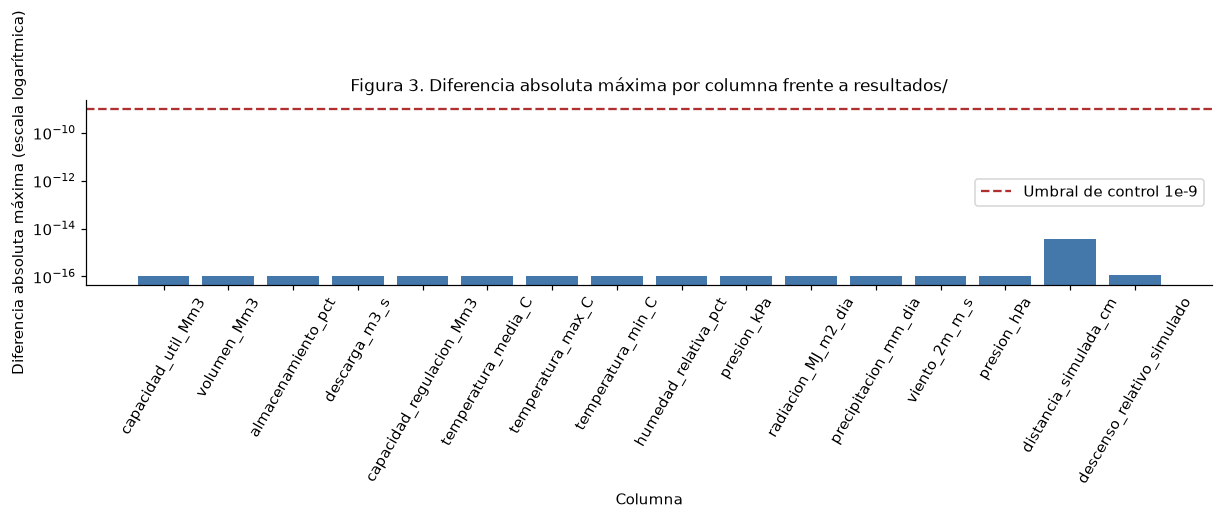

In [9]:
referencia = (pd.read_csv(RESULTADOS / "datos_neusa_con_distancia_simulada.csv", parse_dates=["fecha"])
              .set_index("fecha").sort_index())
assert len(referencia) == 31 and len(base_mensual) == 31, "La matriz mensual no tiene 31 filas."
assert referencia.index.equals(base_mensual.index), "Las fechas no coinciden con la referencia."
columnas_comunes = [c for c in base_mensual.columns
                    if c in referencia.columns and pd.api.types.is_numeric_dtype(referencia[c])]
diferencias = (base_mensual[columnas_comunes].astype(float)
               - referencia.loc[base_mensual.index, columnas_comunes].astype(float)).abs()
diferencias_max = diferencias.max()
max_diferencia = float(diferencias_max.max())
print(f"Filas: {len(base_mensual)}; columnas comunes comparadas: {len(columnas_comunes)}")
print(f"Diferencia absoluta máxima en columnas comunes: {max_diferencia:.3e}")
assert max_diferencia < 1e-9, "La matriz no coincide con resultados/ en las columnas comunes."

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.bar(diferencias_max.index, np.maximum(diferencias_max.to_numpy(), 1e-16), color="#4477AA")
ax.set_yscale("log")
ax.axhline(1e-9, color="#b03030", linestyle="--", label="Umbral de control 1e-9")
ax.set(title="Figura 3. Diferencia absoluta máxima por columna frente a resultados/",
       xlabel="Columna", ylabel="Diferencia absoluta máxima (escala logarítmica)")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.show()

Leyenda de la figura 3: cada barra es la diferencia máxima entre la reconstrucción y el archivo de resultados; todas quedan por debajo del umbral.

In [10]:
registro_preparacion = pd.DataFrame([
    ["CAR", "filas duplicadas por (fecha, embalse)", dup_eliminados_car, "eliminadas"],
    ["CAR", "filas de otros embalses, fuera de la matriz de Neusa", filas_otros_embalses, "no usadas"],
    ["NASA", "días sin volumen CAR en la misma fecha", dias_nasa_sin_volumen, "no usados"],
    ["NASA", "valores de relleno (−999) sustituidos", n_centinela, "sustituidos"],
    ["NASA", "valores imputados por interpolación limitada", imputados_nasa, "imputados"],
], columns=["fuente", "motivo", "conteo", "tratamiento"])
display(registro_preparacion)

,fuente,motivo,conteo,tratamiento
0,CAR,"filas duplicadas por (fecha, embalse)",0,eliminadas
1,CAR,"filas de otros embalses, fuera de la matriz de...",93,no usadas
2,NASA,días sin volumen CAR en la misma fecha,1065,no usados
3,NASA,valores de relleno (−999) sustituidos,0,sustituidos
4,NASA,valores imputados por interpolación limitada,0,imputados


## Punto 3. Valores extremos (diagnóstico)

> **Pregunta:** ¿hay valores extremos que deban quitarse?

Un valor se marca como atípico si queda fuera de Q1 − 1.5·IQR o de Q3 + 1.5·IQR (rango intercuartílico). Este punto solo diagnostica: no se eliminan filas ni se transforma la base. Las columnas constantes tienen rango cero y no se analizan aquí.

Valores atípicos marcados en total: 8
  temperatura_max_C: 2 atípico(s)
  temperatura_min_C: 2 atípico(s)
  humedad_relativa_pct: 2 atípico(s)
  precipitacion_mm_dia: 2 atípico(s)
Filas eliminadas por este punto: 0 (solo diagnóstico).


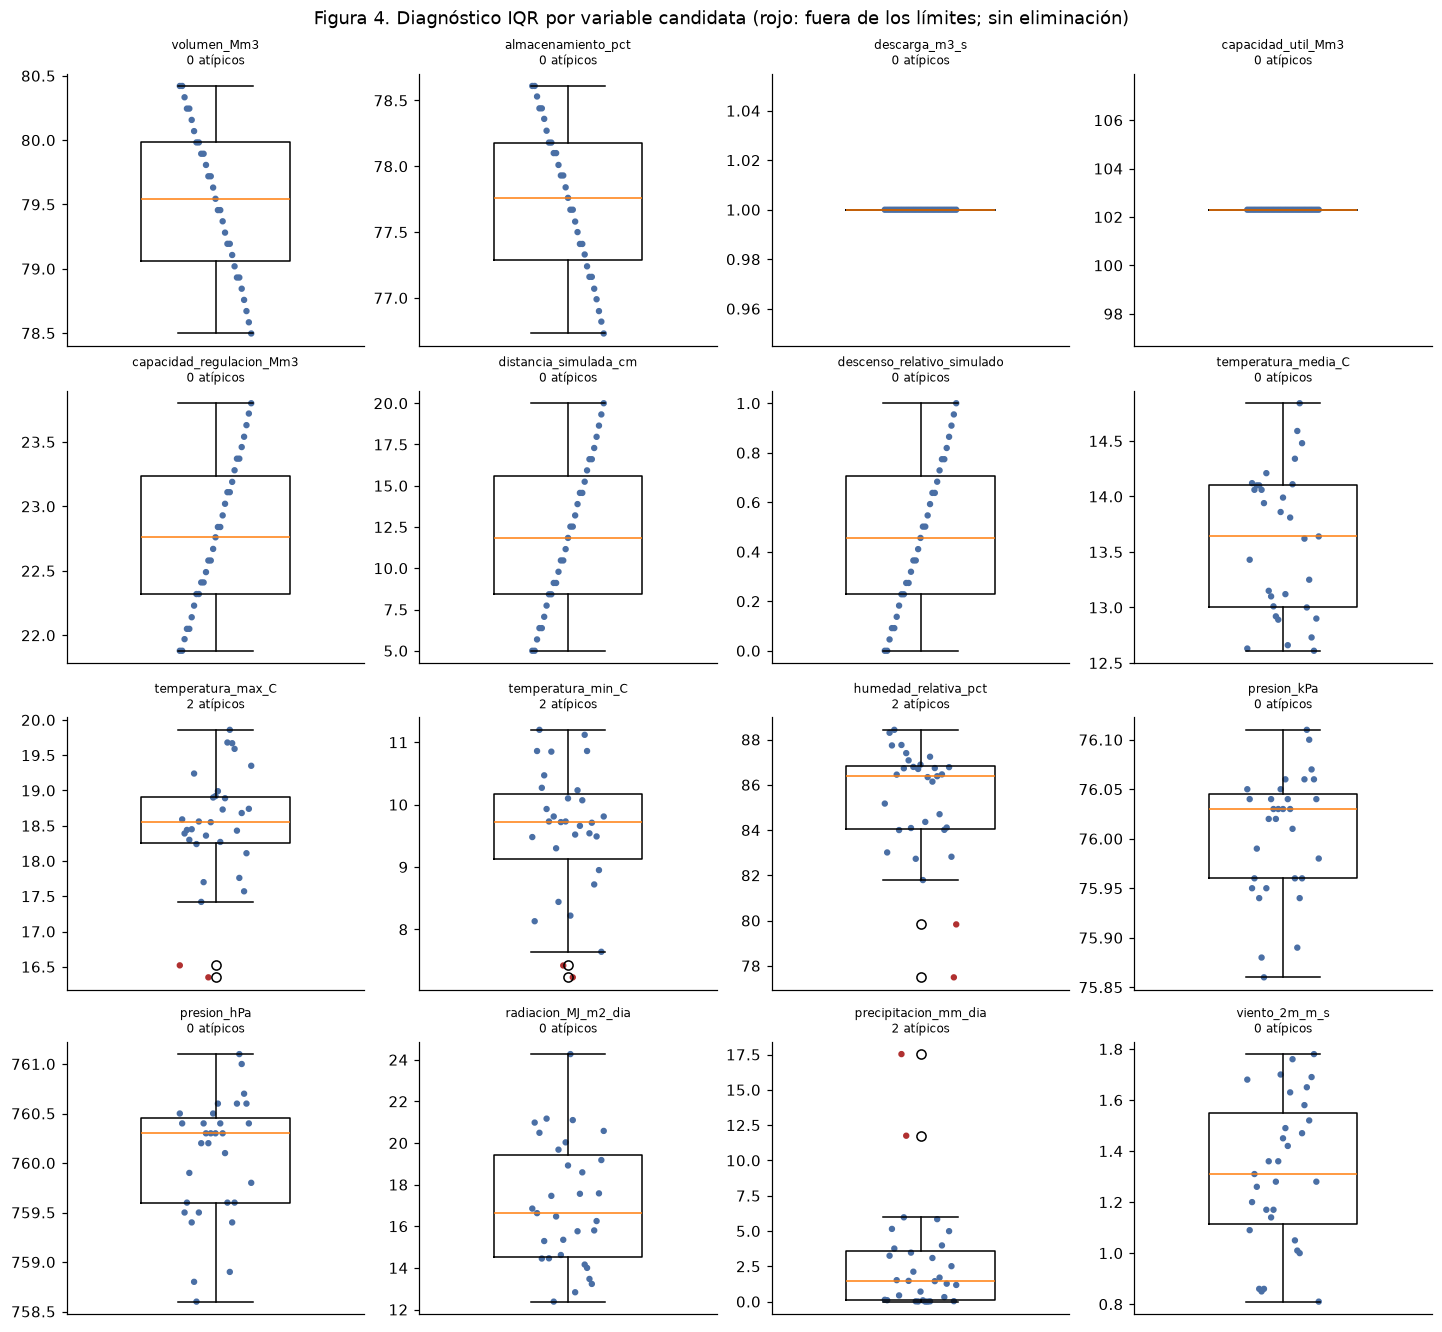

In [11]:
CANDIDATAS = ["volumen_Mm3", "almacenamiento_pct", "descarga_m3_s", "capacidad_util_Mm3",
              "capacidad_regulacion_Mm3", "distancia_simulada_cm", "descenso_relativo_simulado",
              "temperatura_media_C", "temperatura_max_C", "temperatura_min_C",
              "humedad_relativa_pct", "presion_kPa", "presion_hPa", "radiacion_MJ_m2_dia",
              "precipitacion_mm_dia", "viento_2m_m_s"]
assert set(CANDIDATAS) <= set(base_mensual.columns)

def resumen_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bajos = int((serie < inferior).sum())
    altos = int((serie > superior).sum())
    return {"limite_inferior": inferior, "limite_superior": superior,
            "atipicos_total": bajos + altos}

tabla_iqr = pd.DataFrame({c: resumen_iqr(base_mensual[c]) for c in CANDIDATAS}).T
variables_con_atipicos = tabla_iqr.index[tabla_iqr["atipicos_total"] > 0].tolist()
print(f"Valores atípicos marcados en total: {int(tabla_iqr['atipicos_total'].sum())}")
for c in variables_con_atipicos:
    print(f"  {c}: {int(tabla_iqr.loc[c, 'atipicos_total'])} atípico(s)")
print("Filas eliminadas por este punto: 0 (solo diagnóstico).")
assert len(base_mensual) == 31

fig, ejes = plt.subplots(4, 4, figsize=(13, 12), layout="constrained")
for ax, c in zip(ejes.flat, CANDIDATAS):
    serie = base_mensual[c]
    ax.boxplot(serie, widths=0.5)
    fuera = (serie < tabla_iqr.loc[c, "limite_inferior"]) | (serie > tabla_iqr.loc[c, "limite_superior"])
    posicion = 1 + np.linspace(-0.12, 0.12, len(serie))
    ax.scatter(posicion, serie, s=10, c=np.where(fuera, "#b03030", "#4a6fa5"))
    ax.set_xticks([])
    ax.set_title(f"{c}\n{int(tabla_iqr.loc[c, 'atipicos_total'])} atípicos", fontsize=8)
fig.suptitle("Figura 4. Diagnóstico IQR por variable candidata (rojo: fuera de los límites; sin eliminación)")
plt.show()

Leyenda de la figura 4: cada panel es una variable; los puntos rojos quedan fuera de los límites IQR y se conservan en la base.

## Punto 4. Qué variables entran al análisis

> **Pregunta:** ¿qué variables se usan y por qué?

Se mantienen las cinco variables de la fusión definida en el cuaderno 01: la distancia simulada y cuatro variables ambientales. Cada candidata tiene una decisión y un motivo. Una variable se considera redundante si su correlación absoluta con una variable incluida es igual o mayor que `UMBRAL_REDUNDANCIA`. No hay variable de resultado, así que no se usa relación con un objetivo como criterio.

In [12]:
corr = base_mensual[CANDIDATAS].corr()
varianza_candidatas = base_mensual[CANDIDATAS].std(ddof=0)
constantes = varianza_candidatas.index[varianza_candidatas.eq(0)].tolist()
con_varianza = [c for c in CANDIDATAS if c not in constantes]

MOTIVOS = {
    "volumen_Mm3": "Se transforma en distancia_simulada_cm con una relación lineal; se conserva la distancia.",
    "almacenamiento_pct": "Proporcional al volumen publicado; aporta la misma información.",
    "descenso_relativo_simulado": "Transformación lineal de distancia_simulada_cm.",
    "capacidad_util_Mm3": "Constante en el mes para el embalse; varianza nula.",
    "capacidad_regulacion_Mm3": "Constante en el mes para el embalse; varianza nula.",
    "descarga_m3_s": "Variable de CAR fuera de la fusión definida en el cuaderno 01.",
    "temperatura_max_C": "Se conserva temperatura_media_C, como en el cuaderno 01.",
    "temperatura_min_C": "Se conserva temperatura_media_C, como en el cuaderno 01.",
    "presion_kPa": "Misma magnitud que presion_hPa en otra unidad; se conserva hPa.",
    "precipitacion_mm_dia": "Fuera de las cuatro variables ambientales del cuaderno 01.",
    "viento_2m_m_s": "Fuera de las cuatro variables ambientales del cuaderno 01.",
}
assert set(CANDIDATAS) - set(VARIABLES_ACP) <= set(MOTIVOS), "Falta un motivo de exclusión."

filas_seleccion = []
for c in CANDIDATAS:
    if c in VARIABLES_ACP:
        otras = [v for v in VARIABLES_ACP if v != c]
        r_max = float(corr.loc[c, otras].abs().max())
        filas_seleccion.append({"variable": c, "decisión": "incluida", "max_abs_r": r_max,
                                "motivo": "Variable de la fusión del cuaderno 01."})
    else:
        r_max = np.nan if c in constantes else float(corr.loc[c, VARIABLES_ACP].abs().max())
        filas_seleccion.append({"variable": c, "decisión": "excluida", "max_abs_r": r_max,
                                "motivo": MOTIVOS[c]})
tabla_seleccion = pd.DataFrame(filas_seleccion).set_index("variable")
display(tabla_seleccion.round(4))
print("max_abs_r: correlación absoluta máxima con las variables incluidas (vacío si la variable es constante).")

incluidas_corr = corr.loc[VARIABLES_ACP, VARIABLES_ACP].abs().where(~np.eye(len(VARIABLES_ACP), dtype=bool))
assert incluidas_corr.max().max() < UMBRAL_REDUNDANCIA, "Dos variables incluidas son redundantes."
assert all(varianza_candidatas[v] > 0 for v in VARIABLES_ACP)

X = base_mensual[VARIABLES_ACP]
escalador = StandardScaler().fit(X)
Z = pd.DataFrame(escalador.transform(X), index=X.index, columns=VARIABLES_ACP)
assert np.allclose(Z.mean(), 0, atol=1e-12)
assert np.allclose(Z.std(ddof=0), 1)
assert not Z.isna().any().any()
print("Estandarización ajustada sobre la base mensual (31 filas): media 0 y desviación 1 verificadas.")

,decisión,max_abs_r,motivo
variable,,,
volumen_Mm3,excluida,1.0000,Se transforma en distancia_simulada_cm con una...
almacenamiento_pct,excluida,1.0000,Proporcional al volumen publicado; aporta la m...
descarga_m3_s,excluida,NaN,Variable de CAR fuera de la fusión definida en...
capacidad_util_Mm3,excluida,NaN,Constante en el mes para el embalse; varianza ...
capacidad_regulacion_Mm3,excluida,1.0000,Constante en el mes para el embalse; varianza ...
distancia_simulada_cm,incluida,0.4758,Variable de la fusión del cuaderno 01.
descenso_relativo_simulado,excluida,1.0000,Transformación lineal de distancia_simulada_cm.
temperatura_media_C,incluida,0.7221,Variable de la fusión del cuaderno 01.
temperatura_max_C,excluida,0.6880,"Se conserva temperatura_media_C, como en el cu..."


max_abs_r: correlación absoluta máxima con las variables incluidas (vacío si la variable es constante).
Estandarización ajustada sobre la base mensual (31 filas): media 0 y desviación 1 verificadas.


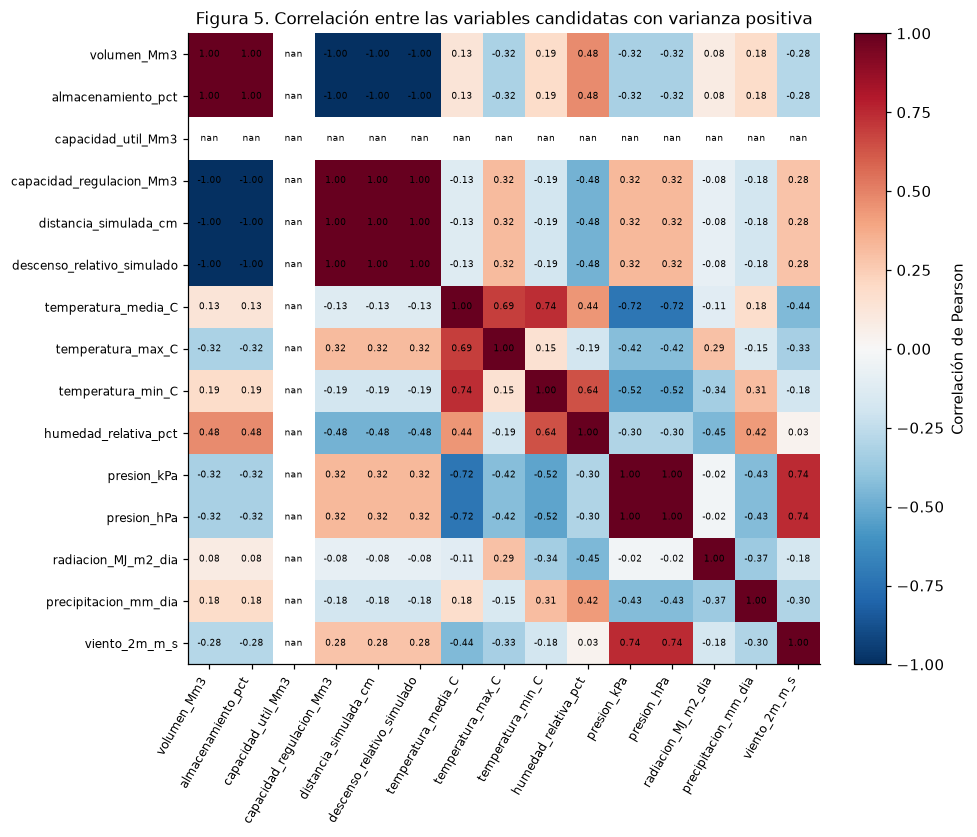

In [13]:
fig, ax = plt.subplots(figsize=(9, 7.5), layout="constrained")
mapa = corr.loc[con_varianza, con_varianza]
im = ax.imshow(mapa.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(con_varianza)), con_varianza, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(con_varianza)), con_varianza, fontsize=8)
for i in range(len(con_varianza)):
    for j in range(len(con_varianza)):
        ax.text(j, i, f"{mapa.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Figura 5. Correlación entre las variables candidatas con varianza positiva")
plt.show()

Leyenda de la figura 5: azul indica correlación negativa y rojo positiva; los valores cercanos a 1 en valor absoluto señalan redundancia.

## Análisis del Parcial 2: proyección por ACP

> **Pregunta:** ¿qué variables cambian juntas?

El ACP busca combinaciones de las variables estandarizadas que resumen su variación conjunta (ver el glosario). Se retienen los primeros componentes hasta que la varianza acumulada alcance `UMBRAL_VARIANZA_ACUMULADA` (80 %). Los signos se fijan para que el coeficiente de `distancia_simulada_cm` en PC1 sea positivo, igual que en el cuaderno 01. Un cambio de signo no altera los porcentajes.

In [14]:
pca = PCA(svd_solver="full").fit(Z)
nombres_pc = [f"PC{i}" for i in range(1, len(VARIABLES_ACP) + 1)]
signos = np.where(pca.components_[:, 0] < 0, -1.0, 1.0)
pca.components_ = pca.components_ * signos[:, None]

varianza_pct = 100 * pca.explained_variance_ratio_
acumulada_pct = np.cumsum(varianza_pct)
n_componentes = int(np.searchsorted(acumulada_pct, UMBRAL_VARIANZA_ACUMULADA) + 1)
assert 2 <= n_componentes <= len(VARIABLES_ACP), "Se necesitan al menos dos componentes para la figura PC1–PC2."
assert abs(varianza_pct.sum() - 100) < 1e-9

tabla_varianza = pd.DataFrame({"componente": nombres_pc, "varianza_pct": varianza_pct,
                               "acumulada_pct": acumulada_pct})
puntajes = pd.DataFrame(pca.transform(Z), index=Z.index, columns=nombres_pc)
coeficientes = pd.DataFrame(pca.components_.T, index=VARIABLES_ACP, columns=nombres_pc)
cargas = pd.DataFrame(np.corrcoef(Z.T, puntajes.T)[:len(VARIABLES_ACP), len(VARIABLES_ACP):],
                      index=VARIABLES_ACP, columns=nombres_pc)
print(f"Componentes retenidos: {n_componentes} (primero con varianza acumulada >= {UMBRAL_VARIANZA_ACUMULADA} %)")
display(tabla_varianza.round(4))
display(coeficientes.round(4))

Componentes retenidos: 3 (primero con varianza acumulada >= 80.0 %)


,componente,varianza_pct,acumulada_pct
0,PC1,45.2739,45.2739
1,PC2,24.3384,69.6123
2,PC3,19.8416,89.4539
3,PC4,7.0016,96.4555
4,PC5,3.5445,100.0000


,PC1,PC2,PC3,PC4,PC5
distancia_simulada_cm,0.3709,0.1403,0.7847,0.2788,0.3863
radiacion_MJ_m2_dia,0.1968,-0.7976,-0.2182,0.4916,0.1894
temperatura_media_C,-0.5326,-0.1927,0.4606,0.3346,-0.5958
humedad_relativa_pct,-0.5187,0.3903,-0.2471,0.5547,0.4580
presion_hPa,0.5205,0.3933,-0.2516,0.5108,-0.5001


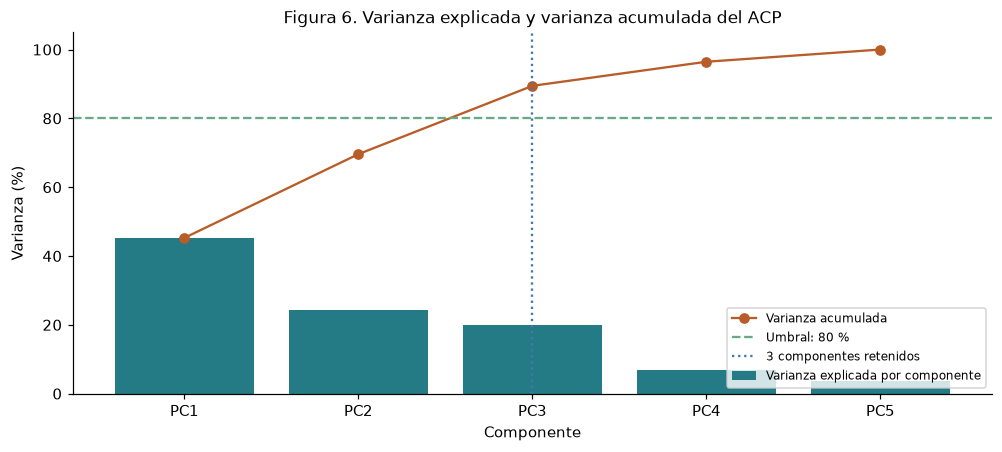

In [15]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(nombres_pc, varianza_pct, color="#247b86", label="Varianza explicada por componente")
ax.plot(nombres_pc, acumulada_pct, "o-", color="#b85c28", label="Varianza acumulada")
ax.axhline(UMBRAL_VARIANZA_ACUMULADA, color="#66AA88", linestyle="--", label=f"Umbral: {UMBRAL_VARIANZA_ACUMULADA:.0f} %")
ax.axvline(n_componentes - 1, color="#4477AA", linestyle=":", label=f"{n_componentes} componentes retenidos")
ax.set(title="Figura 6. Varianza explicada y varianza acumulada del ACP",
       xlabel="Componente", ylabel="Varianza (%)", ylim=(0, 105))
ax.legend(fontsize=8, loc="lower right")
plt.show()

Leyenda de la figura 6: las barras son la varianza de cada componente y la línea la suma acumulada; el umbral marca el criterio de retención.

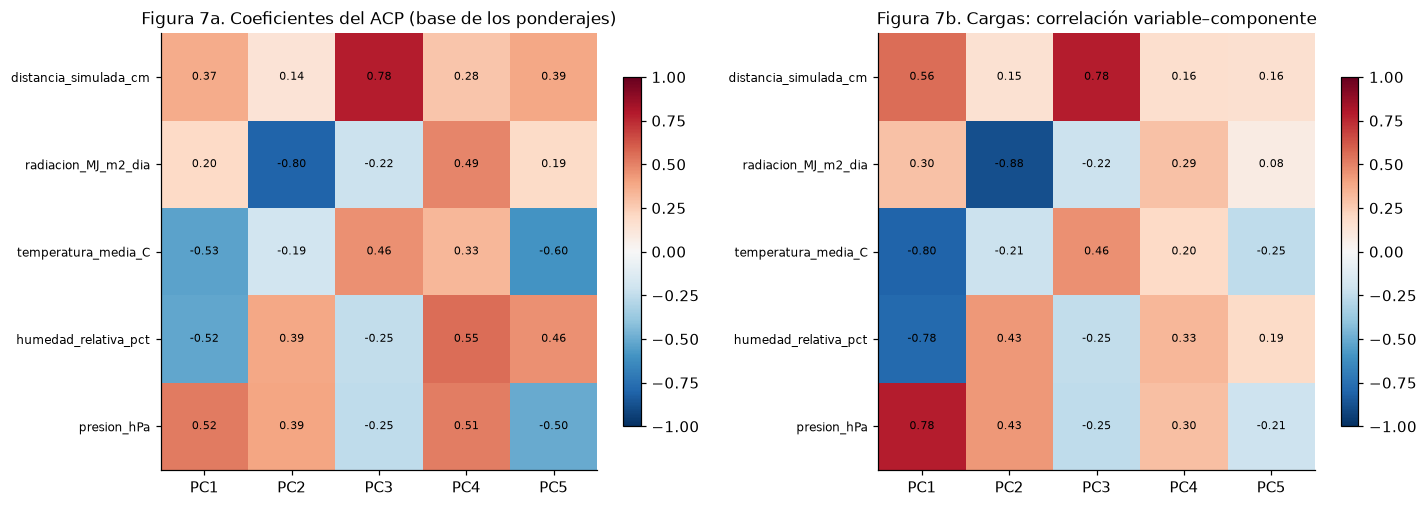

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, tabla, titulo in [(ejes[0], coeficientes, "Figura 7a. Coeficientes del ACP (base de los ponderajes)"),
                          (ejes[1], cargas, "Figura 7b. Cargas: correlación variable–componente")]:
    im = ax.imshow(tabla.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(tabla.shape[1]), tabla.columns)
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=8)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            ax.text(j, i, f"{tabla.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Leyenda de la figura 7: a la izquierda, los pesos con los que cada variable forma cada componente; a la derecha, la correlación de cada variable con cada componente.

## Análisis del Parcial 2: agrupamiento con K-means

> **Pregunta:** ¿las observaciones se parecen en grupos?

Se ajusta K-means sobre los componentes retenidos para k entre 1 y `K_MAX`. Para cada k se calculan la inercia (codo), la silueta, el índice de Davies–Bouldin y el índice de Calinski–Harabasz. El codo se identifica como el punto de mayor distancia a la recta entre los extremos de la curva. Cada criterio propone un k; gana el de más votos y, en empate, el de mayor silueta. La estabilidad se mide con el índice de Rand ajustado (ARI) entre cinco semillas.

In [17]:
X_cl = puntajes.iloc[:, :n_componentes]
candidatos = list(range(2, K_MAX + 1))

def codo_por_distancia(ks, inercias):
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inercias, dtype=float)
    x = (x - x[0]) / (x[-1] - x[0])
    y = (y - y[-1]) / (y[0] - y[-1])
    distancia = np.abs(y - (1 - x))
    return int(np.asarray(ks)[int(np.argmax(distancia))])

filas_metricas = []
for k in range(1, K_MAX + 1):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA_PRINCIPAL).fit(X_cl)
    fila = {"k": k, "inercia": modelo.inertia_}
    if k >= 2:
        fila["silueta"] = silhouette_score(X_cl, modelo.labels_)
        fila["davies_bouldin"] = davies_bouldin_score(X_cl, modelo.labels_)
        fila["calinski_harabasz"] = calinski_harabasz_score(X_cl, modelo.labels_)
    filas_metricas.append(fila)
metricas = pd.DataFrame(filas_metricas).set_index("k")
display(metricas.round(4))

k_codo = codo_por_distancia(candidatos, metricas.loc[candidatos, "inercia"].to_numpy())
criterios = pd.Series({
    "codo": k_codo,
    "silueta (máxima)": int(metricas.loc[candidatos, "silueta"].idxmax()),
    "Davies–Bouldin (mínimo)": int(metricas.loc[candidatos, "davies_bouldin"].idxmin()),
    "Calinski–Harabasz (máximo)": int(metricas.loc[candidatos, "calinski_harabasz"].idxmax()),
}, name="k propuesto")
display(criterios.to_frame())
votos = Counter(criterios.to_list())
k_elegido = max(candidatos, key=lambda k: (votos.get(k, 0), metricas.loc[k, "silueta"]))
assert k_elegido in candidatos
print(f"Votos por k: {dict(sorted(votos.items()))}; k elegido (desempate por silueta): {k_elegido}")

filas_estabilidad = []
for k in candidatos:
    ajustes = [KMeans(n_clusters=k, n_init=10, random_state=s).fit(X_cl) for s in SEMILLAS_ESTABILIDAD]
    particiones = [a.labels_ for a in ajustes]
    pares = [adjusted_rand_score(a, b) for i, a in enumerate(particiones) for b in particiones[i + 1:]]
    inercias = [a.inertia_ for a in ajustes]
    filas_estabilidad.append({"k": k, "ARI_medio": float(np.mean(pares)), "ARI_minimo": float(np.min(pares)),
                              "inercia_minima": min(inercias), "inercia_maxima": max(inercias)})
estabilidad = pd.DataFrame(filas_estabilidad).set_index("k")
display(estabilidad.round(4))
print(f"Pares de particiones por k: {len(SEMILLAS_ESTABILIDAD) * (len(SEMILLAS_ESTABILIDAD) - 1) // 2}")

,inercia,silueta,davies_bouldin,calinski_harabasz
k,,,,
1,138.6536,NaN,NaN,NaN
2,86.0541,0.3082,1.1944,17.7259
3,61.4373,0.3107,1.0738,17.5956
4,49.2311,0.2833,0.9925,16.3474
5,40.2547,0.2725,1.0991,15.8886
6,31.4094,0.3105,0.8573,17.0720


,k propuesto
codo,3
silueta (máxima),3
Davies–Bouldin (mínimo),6
Calinski–Harabasz (máximo),2


Votos por k: {2: 1, 3: 2, 6: 1}; k elegido (desempate por silueta): 3


,ARI_medio,ARI_minimo,inercia_minima,inercia_maxima
k,,,,
2,0.8143,0.5358,86.0541,86.5598
3,0.9556,0.8889,61.4373,61.5279
4,0.8076,0.6696,48.3766,49.6894
5,0.8503,0.7618,38.1673,40.9252
6,0.7626,0.6503,30.7626,31.2706


Pares de particiones por k: 10


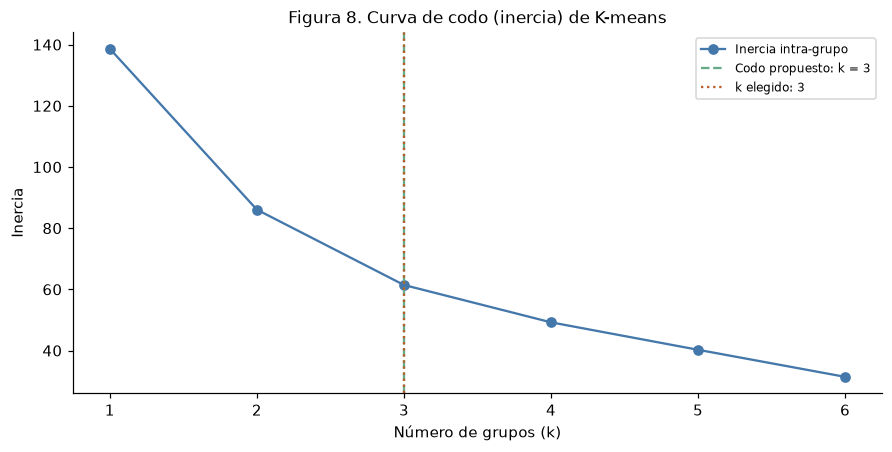

In [18]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(metricas.index, metricas["inercia"], "o-", color="#4477AA", label="Inercia intra-grupo")
ax.axvline(k_codo, color="#66AA88", linestyle="--", label=f"Codo propuesto: k = {k_codo}")
ax.axvline(k_elegido, color="#b85c28", linestyle=":", label=f"k elegido: {k_elegido}")
ax.set(title="Figura 8. Curva de codo (inercia) de K-means", xlabel="Número de grupos (k)",
       ylabel="Inercia", xticks=metricas.index)
ax.legend(fontsize=8)
plt.show()

Leyenda de la figura 8: la inercia baja al aumentar k; el codo y el k elegido se marcan con líneas verticales.

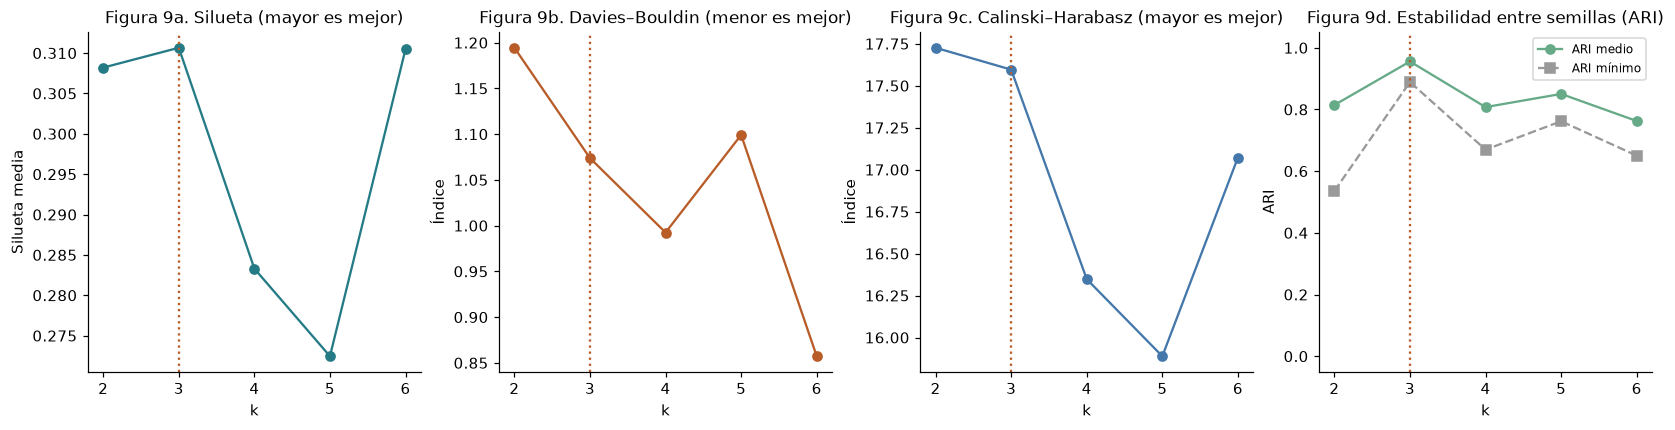

In [19]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.8), layout="constrained")
ejes[0].plot(candidatos, metricas.loc[candidatos, "silueta"], "o-", color="#247b86")
ejes[0].set(title="Figura 9a. Silueta (mayor es mejor)", xlabel="k", ylabel="Silueta media")
ejes[1].plot(candidatos, metricas.loc[candidatos, "davies_bouldin"], "o-", color="#b85c28")
ejes[1].set(title="Figura 9b. Davies–Bouldin (menor es mejor)", xlabel="k", ylabel="Índice")
ejes[2].plot(candidatos, metricas.loc[candidatos, "calinski_harabasz"], "o-", color="#4477AA")
ejes[2].set(title="Figura 9c. Calinski–Harabasz (mayor es mejor)", xlabel="k", ylabel="Índice")
ejes[3].plot(candidatos, estabilidad["ARI_medio"], "o-", color="#66AA88", label="ARI medio")
ejes[3].plot(candidatos, estabilidad["ARI_minimo"], "s--", color="#999999", label="ARI mínimo")
ejes[3].set(title="Figura 9d. Estabilidad entre semillas (ARI)", xlabel="k", ylabel="ARI", ylim=(-0.05, 1.05))
ejes[3].legend(fontsize=8)
for ax in ejes:
    ax.axvline(k_elegido, color="#b85c28", linestyle=":")
    ax.set_xticks(candidatos)
plt.show()

Leyenda de la figura 9: cuatro criterios por número de grupos; la línea punteada marca el k elegido.

,observaciones,silueta_media
grupo,,
1,10,0.3342
2,14,0.3373
3,7,0.2237


Silueta media del agrupamiento: 0.3107
Observaciones con silueta negativa: 3.2258 %


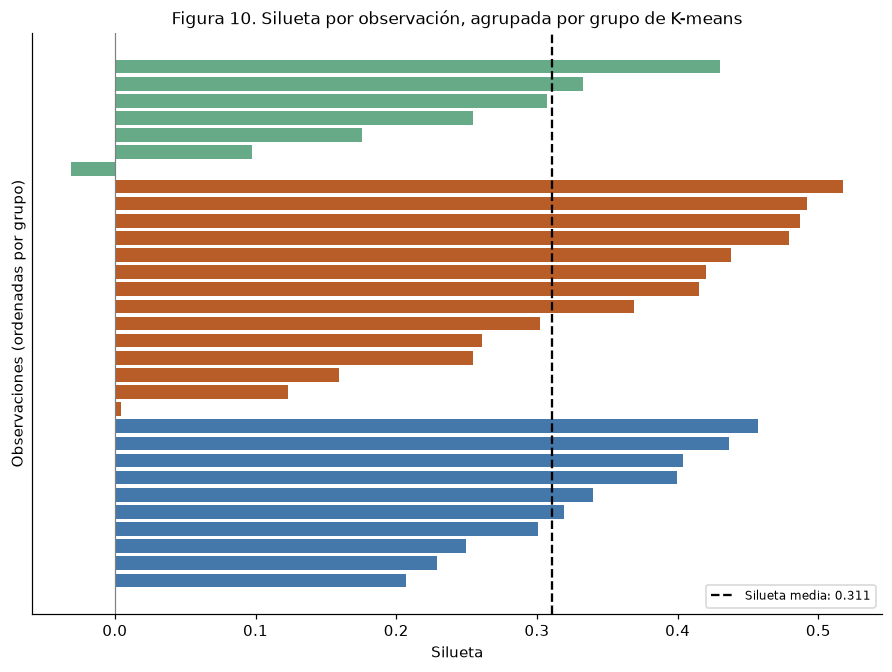

In [20]:
modelo_final = KMeans(n_clusters=k_elegido, n_init=10, random_state=SEMILLA_PRINCIPAL).fit(X_cl)
etiquetas = pd.Series(modelo_final.labels_ + 1, index=X_cl.index, name="grupo")
assert etiquetas.nunique() == k_elegido
muestras_silueta = silhouette_samples(X_cl, etiquetas)
silueta_media = float(silhouette_score(X_cl, etiquetas))
pct_silueta_negativa = 100 * float(np.mean(muestras_silueta < 0))
resumen_grupos = pd.DataFrame({"observaciones": etiquetas.value_counts().sort_index(),
                               "silueta_media": pd.Series(muestras_silueta, index=etiquetas.index)
                               .groupby(etiquetas).mean()})
display(resumen_grupos.round(4))
print(f"Silueta media del agrupamiento: {silueta_media:.4f}")
print(f"Observaciones con silueta negativa: {pct_silueta_negativa:.4f} %")

colores_grupo = {1: "#4477AA", 2: "#b85c28", 3: "#66AA88", 4: "#AA3377", 5: "#999933", 6: "#882255"}
silueta_df = pd.DataFrame({"grupo": etiquetas, "silueta": muestras_silueta}).sort_values(["grupo", "silueta"])
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.barh(range(len(silueta_df)), silueta_df["silueta"], color=[colores_grupo[g] for g in silueta_df["grupo"]])
ax.axvline(silueta_media, color="black", linestyle="--", label=f"Silueta media: {silueta_media:.3f}")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(title="Figura 10. Silueta por observación, agrupada por grupo de K-means",
       xlabel="Silueta", ylabel="Observaciones (ordenadas por grupo)")
ax.set_yticks([])
ax.legend(fontsize=8)
plt.show()

Leyenda de la figura 10: cada barra es una observación; los colores indican el grupo y las barras negativas señalan observaciones más cercanas a otro grupo.

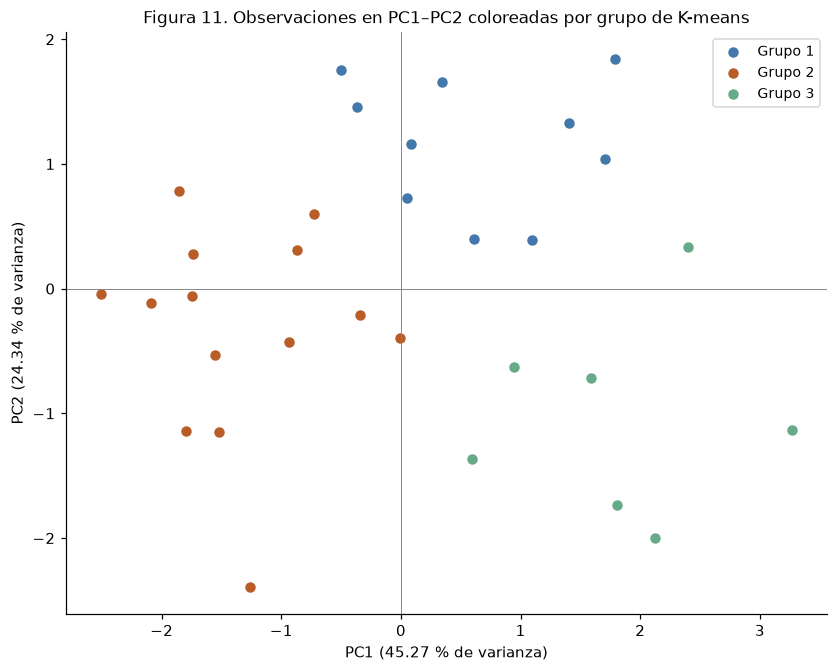

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 6), layout="constrained")
for g in sorted(etiquetas.unique()):
    mascara = etiquetas.eq(g)
    ax.scatter(puntajes.loc[mascara, "PC1"], puntajes.loc[mascara, "PC2"], s=34,
               color=colores_grupo[g], label=f"Grupo {g}")
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set(title="Figura 11. Observaciones en PC1–PC2 coloreadas por grupo de K-means",
       xlabel=f"PC1 ({varianza_pct[0]:.2f} % de varianza)", ylabel=f"PC2 ({varianza_pct[1]:.2f} % de varianza)")
ax.legend(fontsize=9)
plt.show()

Leyenda de la figura 11: cada punto es un día; los colores indican el grupo asignado por K-means.

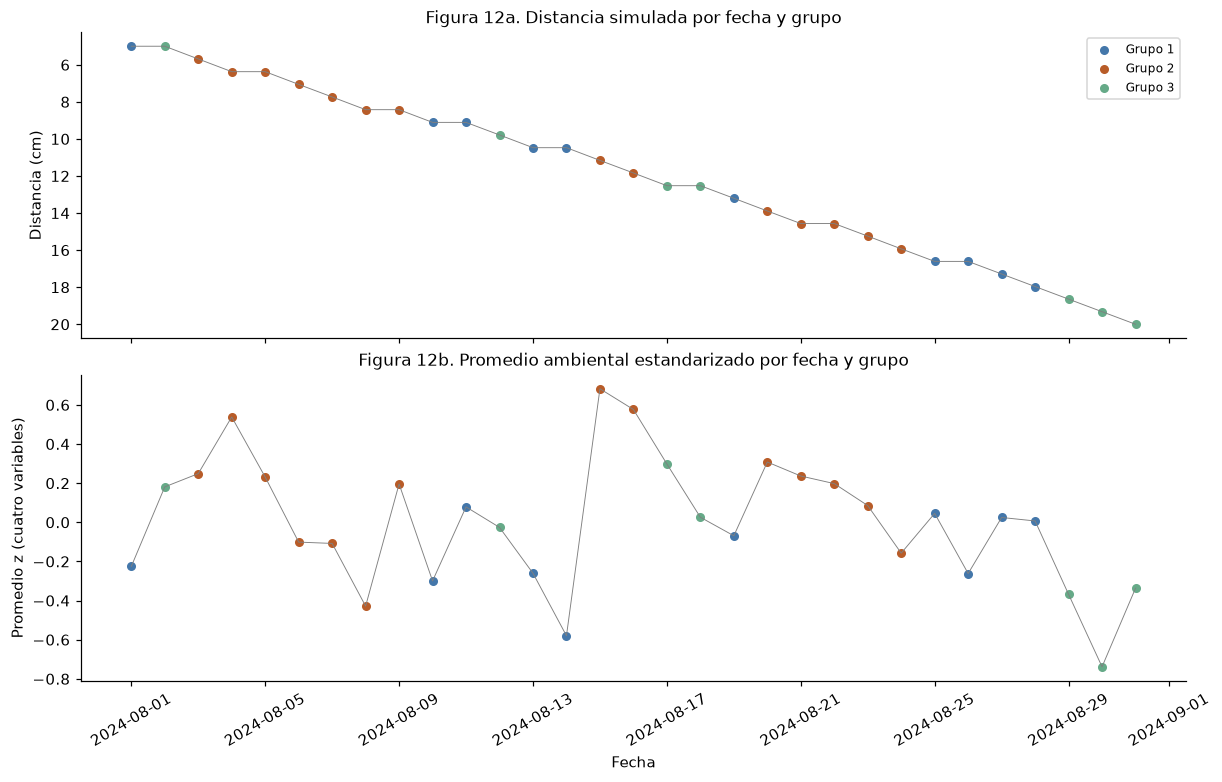

In [22]:
promedio_ambiental = Z[BLOQUE_AMBIENTAL].mean(axis=1)
fig, ejes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")
for g in sorted(etiquetas.unique()):
    mascara = etiquetas.eq(g)
    ejes[0].scatter(base_mensual.index[mascara], base_mensual.loc[mascara, "distancia_simulada_cm"],
                    s=24, color=colores_grupo[g], label=f"Grupo {g}")
    ejes[1].scatter(base_mensual.index[mascara], promedio_ambiental[mascara],
                    s=24, color=colores_grupo[g], label=f"Grupo {g}")
ejes[0].plot(base_mensual.index, base_mensual["distancia_simulada_cm"], color="gray", linewidth=0.6)
ejes[0].invert_yaxis()
ejes[0].set(title="Figura 12a. Distancia simulada por fecha y grupo", ylabel="Distancia (cm)")
ejes[1].plot(promedio_ambiental.index, promedio_ambiental.to_numpy(), color="gray", linewidth=0.6)
ejes[1].set(title="Figura 12b. Promedio ambiental estandarizado por fecha y grupo",
            ylabel="Promedio z (cuatro variables)", xlabel="Fecha")
ejes[1].tick_params(axis="x", rotation=30)
ejes[0].legend(fontsize=8)
plt.show()

Leyenda de la figura 12: arriba, la distancia simulada por día; abajo, el promedio de las cuatro variables ambientales estandarizadas; colores por grupo.

## Ponderajes finales

> **Pregunta:** ¿cuánto pesa cada variable en PC1?

Los ponderajes finales usan el método cuadrático sobre el coeficiente de PC1. La celda vuelve a calcularlos desde la base construida con las fuentes crudas y verifica que coinciden con la tabla de la primera sección. La figura 13 muestra cada ponderaje con su intervalo bootstrap.

Verificado: ponderajes y bootstrap desde fuentes crudas coinciden con la primera sección.


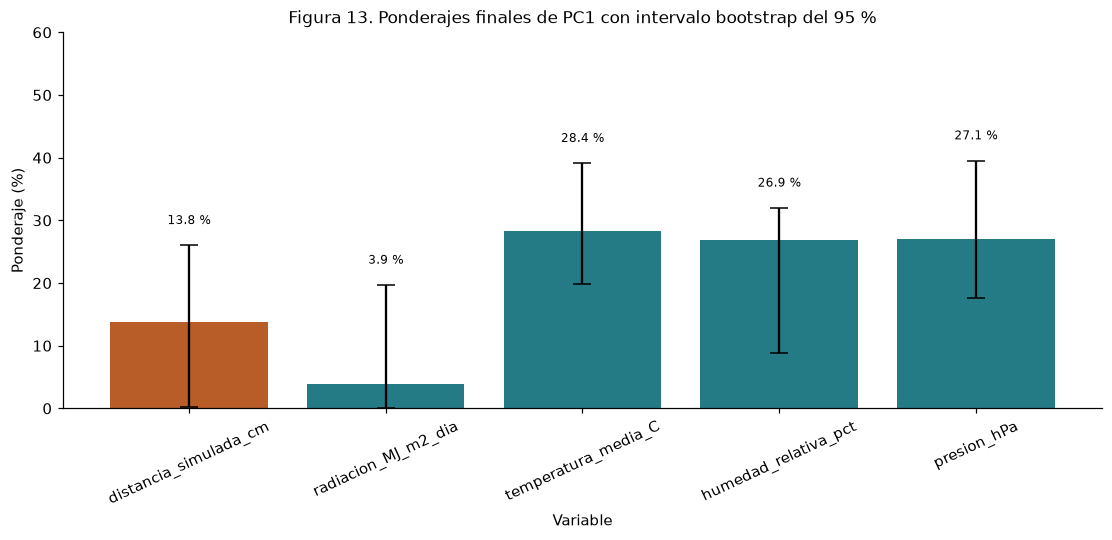

In [23]:
X_det = base_mensual[VARIABLES_ACP].to_numpy(float)
a_det, cuad_det, l1_det = ponderajes_pc1(X_det)
assert np.allclose(cuad_det, resumen_pagina["ponderaje_final_pct"].to_numpy(), atol=1e-9)
assert np.allclose(l1_det, resumen_pagina["sensibilidad_L1_pct"].to_numpy(), atol=1e-9)
assert np.allclose(coeficientes["PC1"].to_numpy(), a_det) or np.allclose(coeficientes["PC1"].to_numpy(), -a_det)
cuad_boot_det, l1_boot_det, alin_det = bootstrap_ponderajes(X_det, a_det)
assert np.allclose(cuad_boot_det, cuad_boot, atol=1e-9), "El bootstrap no coincide entre fuentes crudas y matriz."
print("Verificado: ponderajes y bootstrap desde fuentes crudas coinciden con la primera sección.")

err_inf = resumen_pagina["ponderaje_final_pct"] - resumen_pagina["IC95_inferior_pct"]
err_sup = resumen_pagina["IC95_superior_pct"] - resumen_pagina["ponderaje_final_pct"]
colores_bloque = ["#b85c28"] + ["#247b86"] * len(BLOQUE_AMBIENTAL)
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
barras = ax.bar(VARIABLES_ACP, resumen_pagina["ponderaje_final_pct"], yerr=[err_inf, err_sup],
                capsize=6, color=colores_bloque, ecolor="black")
ax.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=12)
ax.set(title="Figura 13. Ponderajes finales de PC1 con intervalo bootstrap del 95 %",
       xlabel="Variable", ylabel="Ponderaje (%)", ylim=(0, 60))
ax.tick_params(axis="x", rotation=25)
plt.show()

Leyenda de la figura 13: cada barra es el ponderaje final; las líneas negras son el intervalo del 95 % obtenido con 1000 remuestreos.

## Sustento: intervalos de confianza

> **Pregunta:** ¿qué tan seguros son los pesos?

Se remuestrean las 31 filas con reemplazo 1000 veces (semilla 42). En cada remuestreo se repite el ACP completo y se guarda el ponderaje de cada variable. Los límites del intervalo son los percentiles 2,5 y 97,5. Como el PC1 de un remuestreo puede girar respecto del original, también se mide la alineación: el valor absoluto del coseno entre ambos vectores de coeficientes.

Ancho de los intervalos (puntos porcentuales): distancia_simulada_cm: 25.85, radiacion_MJ_m2_dia: 19.66, temperatura_media_C: 19.21, humedad_relativa_pct: 23.17, presion_hPa: 21.88
Intervalo más ancho: distancia_simulada_cm (25.85 puntos porcentuales).
Remuestreos con PC1 alineado con el original (|coseno| >= 0.9): 92.50 %


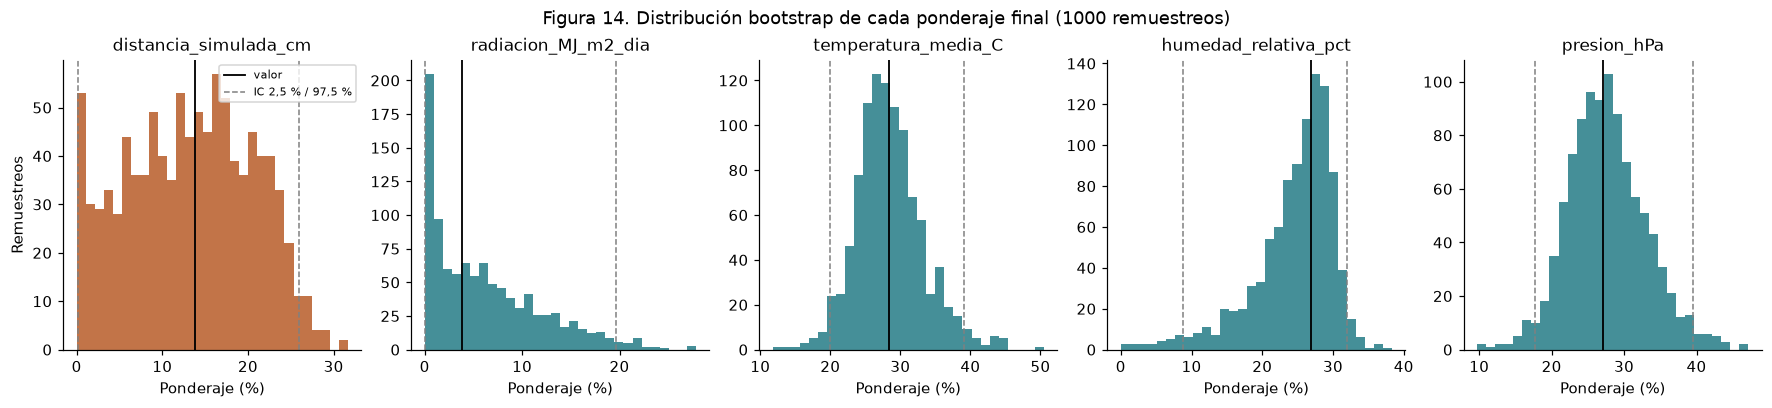

In [24]:
ancho = pd.Series(ic_sup - ic_inf, index=VARIABLES_ACP)
variable_mas_ancha = ancho.idxmax()
print(f"Ancho de los intervalos (puntos porcentuales): " + ", ".join(f"{v}: {w:.2f}" for v, w in ancho.items()))
print(f"Intervalo más ancho: {variable_mas_ancha} ({ancho.max():.2f} puntos porcentuales).")
print(f"Remuestreos con PC1 alineado con el original (|coseno| >= {UMBRAL_ALINEACION}): "
      f"{100 * np.mean(alin_boot >= UMBRAL_ALINEACION):.2f} %")

fig, ejes = plt.subplots(1, 5, figsize=(16, 3.6), layout="constrained")
for i, (ax, v) in enumerate(zip(ejes, VARIABLES_ACP)):
    ax.hist(cuad_boot[:, i], bins=30, color=colores_bloque[i], alpha=0.85)
    ax.axvline(cuad_pt[i], color="black", linewidth=1.2, label="valor")
    ax.axvline(ic_inf[i], color="gray", linestyle="--", linewidth=1, label="IC 2,5 % / 97,5 %")
    ax.axvline(ic_sup[i], color="gray", linestyle="--", linewidth=1)
    ax.set(title=v, xlabel="Ponderaje (%)")
    if i == 0:
        ax.set_ylabel("Remuestreos")
        ax.legend(fontsize=7)
fig.suptitle("Figura 14. Distribución bootstrap de cada ponderaje final (1000 remuestreos)")
plt.show()

Leyenda de la figura 14: cada histograma muestra los 1000 valores del ponderaje; la línea negra es el valor de la muestra y las punteadas el intervalo del 95 %.

## Comparación de métodos

> **Pregunta:** ¿qué variable empuja en qué sentido?

La tabla compara tres lecturas del mismo vector de PC1. El **signo** del coeficiente indica el sentido: un coeficiente positivo significa que el puntaje PC1 sube cuando la variable sube. El método L1 reparte el valor absoluto y el cuadrático reparte el cuadrado. Ambos suman 100 %, pero describen cosas distintas.

In [25]:
comparacion = pd.DataFrame({
    "coeficiente_PC1": coeficientes["PC1"],
    "signo": np.where(coeficientes["PC1"] >= 0, "positivo", "negativo"),
    "al_subir_la_variable": np.where(coeficientes["PC1"] >= 0, "PC1 sube", "PC1 baja"),
    "L1_pct": 100 * coeficientes["PC1"].abs() / coeficientes["PC1"].abs().sum(),
    "cuadratico_pct (final)": 100 * coeficientes["PC1"] ** 2 / np.sum(coeficientes["PC1"] ** 2),
})
display(comparacion.round(4))
assert abs(comparacion["L1_pct"].sum() - 100) < 1e-9
assert abs(comparacion["cuadratico_pct (final)"].sum() - 100) < 1e-9

,coeficiente_PC1,signo,al_subir_la_variable,L1_pct,cuadratico_pct (final)
distancia_simulada_cm,0.3709,positivo,PC1 sube,17.3371,13.7595
radiacion_MJ_m2_dia,0.1968,positivo,PC1 sube,9.1970,3.8720
temperatura_media_C,-0.5326,negativo,PC1 baja,24.8941,28.3690
humedad_relativa_pct,-0.5187,negativo,PC1 baja,24.2455,26.9099
presion_hPa,0.5205,positivo,PC1 sube,24.3263,27.0895


## Qué no demuestra este análisis

- Se usan **31 observaciones diarias de un solo mes** (agosto de 2024) y un solo embalse. Con esa muestra, los pesos y los grupos pueden cambiar con otros días o periodos; el intervalo bootstrap muestra parte de esa incertidumbre, no toda.
- La **distancia es simulada** a partir del volumen publicado. No es una medición del sensor ultrasónico, y los extremos de la escala son los del mes.
- El **ACP describe la estructura común** de las variables: qué cambia junto con qué. No mide riesgo ni predice una alarma.
- Los **ponderajes no son ponderaciones de riesgo validadas**. Las etiquetas de sensor indican una correspondencia prevista, no una calibración.
- El **80/20 del firmware no se reproduce** con estos datos (ver la celda siguiente con la cifra calculada). Ninguna cifra de este cuaderno valida un umbral de alarma.

In [26]:
REFERENCIA_FIRMWARE_NIVEL_PCT = 80.0  # referencia declarada en el firmware; no validada
nivel_cuad = float(resumen_pagina.loc["distancia_simulada_cm", "ponderaje_final_pct"])
nivel_l1 = float(resumen_pagina.loc["distancia_simulada_cm", "sensibilidad_L1_pct"])
comparacion_nivel = pd.DataFrame({
    "nivel_calculado_pct": [nivel_cuad, nivel_l1],
    "referencia_firmware_pct": [REFERENCIA_FIRMWARE_NIVEL_PCT] * 2,
}, index=["cuadrático (final)", "L1"])
comparacion_nivel["diferencia_pp"] = comparacion_nivel["nivel_calculado_pct"] - comparacion_nivel["referencia_firmware_pct"]
display(comparacion_nivel.round(4))
print(f"Participación del nivel: {nivel_cuad:.2f} % (cuadrático) y {nivel_l1:.2f} % (L1), frente a {REFERENCIA_FIRMWARE_NIVEL_PCT:.0f} % de referencia.")
print("Solo se muestra la diferencia; la referencia 80/20 no se valida en este cuaderno.")

,nivel_calculado_pct,referencia_firmware_pct,diferencia_pp
cuadrático (final),13.7595,80.0,-66.2405
L1,17.3371,80.0,-62.6629


Participación del nivel: 13.76 % (cuadrático) y 17.34 % (L1), frente a 80 % de referencia.
Solo se muestra la diferencia; la referencia 80/20 no se valida en este cuaderno.


## Montaje del sensor y porcentaje de volumen

> **Pregunta:** ¿a qué altura conviene montar el sensor, y cómo se pasa de nivel a porcentaje de volumen?

### Montaje del sensor

**Qué dice la evidencia.** No existe una regla general para la altura de montaje de un sensor ultrasónico sobre un embalse. En las fuentes consultadas se recomienda montarlo por encima del nivel máximo esperado, con al menos la distancia de zona ciega (*blanking*) del modelo y un margen adicional. La zona ciega depende del modelo: en las fuentes consultadas va de unas 4 a 12 pulgadas, hasta cerca de 1,5 pies en sensores grandes. Un modelo de NCD indica 500 mm de zona ciega.

- [Silver Instruments: ultrasonic sensors and blanking distance](https://www.silverinstruments.com/blog/ultrasonic-sensors-and-blanking-distance)
- [NCD: guía de instalación de un sensor ultrasónico de nivel](https://ncd.io/blog/ultrasonic-long-range-wireless-tank-level-sensor-installation-guide/). Para ese mismo modelo, la altura de instalación indicada es de al menos 550 mm sobre el nivel lleno.
- [APG Sensors: lista de verificación de instalación](https://apgsensors.com/ultrasonic-level-sensor-installation-checklist/)
- Para el SR50A, el manual de Vaisala citado en el cuaderno 01 [7] indica al menos 50 cm sobre el nivel máximo esperado. Es una instrucción de ese equipo, no una altura universal.

**Lo que documenta el curso.** En la maqueta del reto, el HC-SR04 mide la distancia a la superficie del agua. El firmware usa valores provisionales de distancia. La cifra de una altura de un metro no aparece en las fuentes citadas en este cuaderno; debe confirmarse con una fuente antes de usarla.

**Resultado verificado.** Los ponderajes no cambian con la altura de montaje. La celda siguiente transforma la distancia *d* en *H − d* para cuatro alturas *H* y recalcula los ponderajes de PC1. El ACP sobre variables estandarizadas no depende de desplazamiento ni de escala, así que los cuatro casos dan los mismos valores que la tabla de la primera sección.

**Advertencia.** Esta invariancia vale solo si la distancia es una función lineal del volumen. Con una curva cota–volumen real, que no es lineal, los pesos sí podrían cambiar.

**Lo que sí cambia con la altura.** El rango numérico de la distancia y los umbrales de alarma en centímetros. Por eso la altura de montaje debe medirse en el recipiente real. No se recomienda una altura única: el valor adecuado depende del modelo del sensor y del montaje físico.

In [27]:
alturas_montaje = [30, 50, 100, 130]
ponderajes_por_altura = pd.DataFrame(
    {f"H = {H} cm": ponderajes_pc1(np.column_stack([H - X_det[:, 0], X_det[:, 1:]]))[1]
     for H in alturas_montaje},
    index=VARIABLES_ACP)
display(ponderajes_por_altura.round(4))
for H in alturas_montaje:
    assert np.allclose(ponderajes_por_altura[f"H = {H} cm"].to_numpy(), cuad_det, atol=1e-9), \
        f"Cambia el ponderaje con H = {H} cm"
print("Los ponderajes finales son iguales en todas las alturas de la comprobación (tolerancia 1e-9).")

,H = 30 cm,H = 50 cm,H = 100 cm,H = 130 cm
distancia_simulada_cm,13.7595,13.7595,13.7595,13.7595
radiacion_MJ_m2_dia,3.8720,3.8720,3.8720,3.8720
temperatura_media_C,28.3690,28.3690,28.3690,28.3690
humedad_relativa_pct,26.9099,26.9099,26.9099,26.9099
presion_hPa,27.0895,27.0895,27.0895,27.0895


Los ponderajes finales son iguales en todas las alturas de la comprobación (tolerancia 1e-9).


### Normas y referencias

Esta subsección resume lo que se encontró en normas y guías. No constituye una especificación técnica ni sustituye la del fabricante del sensor.

- **ISO 4373:2022**. Según resúmenes secundarios, la norma trata la medición de nivel de agua; regula desempeño, instalación e incertidumbre, y se aplica también a equipos ultrasónicos. En esos resúmenes no aparece una altura fija; se mencionan el haz perpendicular a la superficie y un soporte rígido. El texto completo no fue consultado. Enlace: [ISO 4373:2022 en la tienda de ANSI](https://webstore.ansi.org/standards/iso/ISO43732022).
- **WMO (guías de hidrometría).** No se confirmó el texto sobre distancia mínima del sensor. No se cita un enlace de respaldo para este punto.
- **Colombia.** No se encontró una norma ni un protocolo del IDEAM que fije la distancia del sensor en embalses ni en presas. Enlace de referencia: IDEAM, monitoreo (enlace no disponible; no verificado). Para la seguridad de presas, la Ley 1523 de 2012 (gestión del riesgo de desastres) apareció en la búsqueda, pero no fue revisada.

**Conclusión de práctica, no de norma.** En la búsqueda realizada no se encontró un número oficial aplicable en Colombia para esta distancia. La práctica de los proveedores consultados es montar el sensor por encima del nivel máximo esperado, más la zona ciega del modelo y con margen. Esta conclusión se apoya en las fuentes anteriores.

### Porcentaje de volumen

**Método general.** El nivel se convierte en volumen con la curva cota–volumen del embalse. El porcentaje de llenado útil es (V almacenado − V muerto) / V máximo útil × 100, donde V muerto es el volumen por debajo de la cota mínima de operación. Este método es general y no sustituye la metodología oficial de la CAR. El concepto de volumen útil se describe en el [reporte de embalses de Superservicios (marzo de 2026)](https://www.superservicios.gov.co/sites/default/files/2026-03/Reporte-de-Embalses-Superservicios-20-03-2026.pdf).

**Precisión.** La diferencia entre el porcentaje publicado y el recalculado es de precisión de publicación y de la curva, no de un cálculo distinto. La CAR publica cifras con decimales. El control de redondeo está en `resultados/control_redondeo_CAR.csv` y se resume en la celda siguiente.

In [28]:
control_redondeo = pd.read_csv(BASE / "resultados/control_redondeo_CAR.csv")
print(f"Filas de control de redondeo: {len(control_redondeo)}")
print(f"Filas compatibles con el porcentaje publicado: {int(control_redondeo['compatible_porcentaje'].sum())} de {len(control_redondeo)}")
print(f"Diferencia absoluta máxima (puntos porcentuales): {control_redondeo['diferencia_puntos_porcentuales'].abs().max():.4f}")
assert control_redondeo["compatible_porcentaje"].all(), "Hay filas no compatibles con el porcentaje publicado."

Filas de control de redondeo: 124
Filas compatibles con el porcentaje publicado: 124 de 124
Diferencia absoluta máxima (puntos porcentuales): 0.0210


## Resumen de porcentajes

> **Pregunta:** ¿qué porcentajes resultan en total?

Todas las cifras de esta sección salen de las celdas de código. Cada bloque de porcentajes suma 100 %. El cuaderno 01 registra en `resultados/definicion_porcentajes.csv` la participación del nivel en PC1 por los dos métodos; la celda de control compara ese archivo con el cálculo de este cuaderno.

In [29]:
bloques = pd.DataFrame({
    "método": ["L1: |coef| / Σ|coef|", "cuadrático: coef² / Σ coef²"],
    "bloque hídrico (distancia simulada) %": [100 * np.abs(coeficientes.loc["distancia_simulada_cm", "PC1"]) / np.abs(coeficientes["PC1"]).sum(),
                                              100 * coeficientes.loc["distancia_simulada_cm", "PC1"] ** 2 / np.sum(coeficientes["PC1"] ** 2)],
    "bloque ambiental (cuatro variables) %": [100 * np.abs(coeficientes.loc[BLOQUE_AMBIENTAL, "PC1"]).sum() / np.abs(coeficientes["PC1"]).sum(),
                                              100 * (coeficientes.loc[BLOQUE_AMBIENTAL, "PC1"] ** 2).sum() / np.sum(coeficientes["PC1"] ** 2)],
})
bloques["suma %"] = bloques.iloc[:, 1] + bloques.iloc[:, 2]
display(Markdown("**1. Varianza explicada por componente y acumulada (%)**"))
display(tabla_varianza.round(4))
print(f"Suma de la varianza explicada: {varianza_pct.sum():.6f} %")
display(Markdown("**2. Contribución de cada bloque a PC1 (dos métodos distintos)**"))
display(bloques.round(4))
porcentaje_grupos = (100 * etiquetas.value_counts().sort_index() / len(etiquetas)).rename("porcentaje de observaciones %")
display(Markdown("**3. Porcentaje de observaciones por grupo de K-means**"))
display(porcentaje_grupos.round(4).to_frame())
print(f"Suma de porcentajes por grupo: {porcentaje_grupos.sum():.6f} %")
display(Markdown("**4. Silueta negativa**"))
print(f"Porcentaje de observaciones con silueta negativa: {pct_silueta_negativa:.4f} %")
display(Markdown("**5. Ponderajes finales (cuadrático) y sensibilidad (L1)**"))
print(f"Suma de ponderajes finales: {resumen_pagina['ponderaje_final_pct'].sum():.6f} %; suma L1: {resumen_pagina['sensibilidad_L1_pct'].sum():.6f} %")
print(f"k elegido: {k_elegido}; componentes retenidos: {n_componentes}; umbral de varianza acumulada: {UMBRAL_VARIANZA_ACUMULADA} %")

**1. Varianza explicada por componente y acumulada (%)**

,componente,varianza_pct,acumulada_pct
0,PC1,45.2739,45.2739
1,PC2,24.3384,69.6123
2,PC3,19.8416,89.4539
3,PC4,7.0016,96.4555
4,PC5,3.5445,100.0000


Suma de la varianza explicada: 100.000000 %


**2. Contribución de cada bloque a PC1 (dos métodos distintos)**

,método,bloque hídrico (distancia simulada) %,bloque ambiental (cuatro variables) %,suma %
0,L1: |coef| / Σ|coef|,17.3371,82.6629,100.0
1,cuadrático: coef² / Σ coef²,13.7595,86.2405,100.0


**3. Porcentaje de observaciones por grupo de K-means**

... (2 outputs left out)

**4. Silueta negativa**

Porcentaje de observaciones con silueta negativa: 3.2258 %


**5. Ponderajes finales (cuadrático) y sensibilidad (L1)**

Suma de ponderajes finales: 100.000000 %; suma L1: 100.000000 %
k elegido: 3; componentes retenidos: 3; umbral de varianza acumulada: 80.0 %


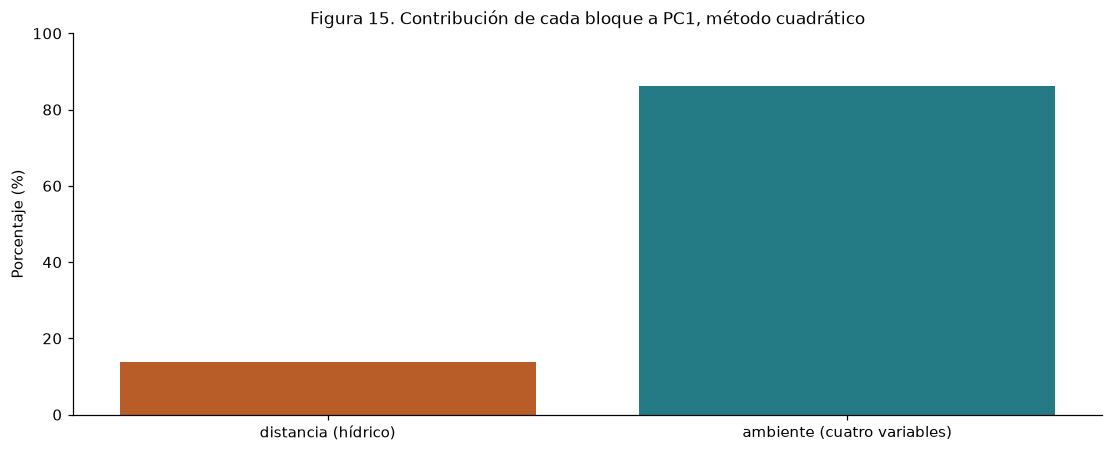

In [30]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(["distancia (hídrico)", "ambiente (cuatro variables)"], bloques.iloc[1, 1:3].to_numpy(dtype=float),
       color=["#b85c28", "#247b86"])
ax.set_ylim(0, 100)
ax.set(title="Figura 15. Contribución de cada bloque a PC1, método cuadrático",
       ylabel="Porcentaje (%)")
plt.show()

Leyenda de la figura 15: participación del bloque hídrico y del bloque ambiental en PC1 con el método cuadrático.

In [31]:
# Autoverificación final
assert abs(varianza_pct.sum() - 100) < 1e-9, "La varianza explicada no suma 100 %."
assert abs(bloques["suma %"].iloc[0] - 100) < 1e-9 and abs(bloques["suma %"].iloc[1] - 100) < 1e-9
assert abs(resumen_pagina["ponderaje_final_pct"].sum() - 100) < 1e-9
assert abs(resumen_pagina["sensibilidad_L1_pct"].sum() - 100) < 1e-9
assert abs(porcentaje_grupos.sum() - 100) < 1e-9
assert len(base_mensual) == 31
assert not base_mensual[VARIABLES_ACP].isna().any().any()
assert not Z.isna().any().any()
assert np.isfinite(pct_silueta_negativa)
definicion_01 = pd.read_csv(BASE / "resultados/definicion_porcentajes.csv").set_index("estadistico")
control_01 = pd.DataFrame({
    "recalculado_pct": [100 * np.abs(coeficientes.loc["distancia_simulada_cm", "PC1"]) / np.abs(coeficientes["PC1"]).sum(),
                        100 * coeficientes.loc["distancia_simulada_cm", "PC1"] ** 2 / np.sum(coeficientes["PC1"] ** 2)],
    "en_01_pct": [definicion_01.loc["Reparto L1 de coeficientes PC1", "nivel_pct"],
                  definicion_01.loc["Contribuciones cuadráticas a PC1", "nivel_pct"]],
}, index=["L1", "cuadrático"])
control_01["diferencia_absoluta"] = (control_01["recalculado_pct"] - control_01["en_01_pct"]).abs()
display(control_01.round(6))
assert control_01["diferencia_absoluta"].max() < 1e-6, "Los porcentajes no coinciden con el cuaderno 01."
print("Autoverificación completada: sumas de porcentajes, ausencia de NaN, 31 filas y control frente al cuaderno 01.")

,recalculado_pct,en_01_pct,diferencia_absoluta
L1,17.3371,17.3371,0.0
cuadrático,13.7595,13.7595,0.0


Autoverificación completada: sumas de porcentajes, ausencia de NaN, 31 filas y control frente al cuaderno 01.


Nota de limitación. La base contiene 31 observaciones diarias de un mes. Las proporciones de varianza, los ponderajes, las contribuciones y las asignaciones de grupo describen esta muestra; su estabilidad depende del tamaño de la muestra y no se extrapola a otros periodos ni embalses.